# Analisis asosiasi gender dan sensitivitas SC-WEAT — KBJI 2014

**Implementasi aktif mulai 14 Oktober 2026.** Notebook linear ini memakai satu model pretrained `cc.id.300.bin`, tanpa pelatihan ulang. Semua hasil dihitung dari input dan model aktual pada run baru; arsip eksperimen tidak dibaca.

1. **RM 1:** arah, effect size, dan signifikansi per 415 jabatan Profesional.
2. **RM 2:** perbandingan **deskriptif** distribusi pada enam Subgolongan Pokok (21–26).
3. **RM 3:** sensitivitas effect size, arah, dan peringkat melalui delapan kondisi leave-one-pair-out (LOPO).

Ketentuan tetap: rata-rata vektor token mentah dengan koefisien sama, normalisasi L2 setelah agregasi, `ddof=0`, permutasi eksak dua sisi 12.870, dan BH-FDR global pada 415 pengujian (`q=0.05`). LOPO memakai 14 atribut tanpa p-value tambahan. Hasil hanya asosiasi intrinsik dalam ruang embedding; bukan bukti diskriminasi atau komposisi tenaga kerja.

Acuan implementasi tersedia di [dokumen revisi](../docs/ACUAN_PROPOSAL_REVISI.md); proposal asli tidak tersedia. Baca [metodologi](../docs/METODOLOGI_IMPLEMENTASI.md) dan [kamus data](../docs/KAMUS_DATA_DAN_OUTPUT.md). Jalankan **Restart Kernel and Run All** dengan environment pada `requirements.txt`.

## 1. Impor, konfigurasi, dan identitas eksekusi

Path ditentukan relatif terhadap root repository sehingga notebook dapat dijalankan dari root atau folder `notebooks/`. Folder run bertimestamp tidak menimpa hasil lama. Seed hanya untuk pemeriksaan pengacakan/jitter; pengujian utama eksak. Toleransi ekstrem hanya mengatasi nilai yang sama secara matematis, sedangkan arah memakai skor belum dibulatkan dengan toleransi nol terpisah `0.0`.

In [1]:
import hashlib, importlib.metadata, itertools, json, platform, re, subprocess, sys, time, unicodedata
from datetime import datetime, timedelta, timezone
from pathlib import Path
from textwrap import fill
import fasttext
import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.spatial.distance import cosine as cosine_distance
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data').is_dir() and (p / '.git').exists())
RANDOM_SEED = 42
RNG = np.random.default_rng(RANDOM_SEED)
JAKARTA = timezone(timedelta(hours=7))
START = datetime.now(JAKARTA)
RUN_ID = 'scweat_' + START.strftime('%Y%m%dT%H%M%S_%f%z')
CONFIG = {
    'data_path': 'data/test1_v5_kbji_profesional_clean.csv',
    'raw_verification_path': 'data/test_v2_kbji_profesional_all.csv',
    'lexicon_path': 'data/test_v2_istilah_gender.csv',
    'lexicon_historical_path': 'data/test1_v5_gender_lexicon.csv',
    'pdf_path': 'data/KBJI 2014.pdf',
    'model_path': 'models/cc.id.300.bin',
    'model_source_url': 'https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.id.300.bin.gz',
    'model_documentation_url': 'https://fasttext.cc/docs/en/crawl-vectors.html',
    'ddof': 0, 'fdr_q': 0.05, 'atol': 1e-12, 'rtol': 1e-12,
    'zero_atol': 0.0, 'random_seed': RANDOM_SEED,
    'group_order': ['21', '22', '23', '24', '25', '26'],
    'expected_group_counts': {'21': 138, '22': 74, '23': 42, '24': 29, '25': 26, '26': 106},
    'preprocessing': {'unicode': 'NFKC', 'lowercase': True, 'quotes_deleted': '\"“”„‟‘’\'',
                      'separators_to_space': '()/,.', 'nonprinting': 'Cc/Cf menjadi spasi',
                      'whitespace': 'collapse lalu strip', 'hyphen': 'dipertahankan',
                      'other_punctuation': 'dipertahankan'},
    'direction_palette': {'positif': '#D55E00', 'negatif': '#7B61A8', 'nol': '#7A7A7A'},
    'figure_dpi': 300, 'top_n_each_direction': 15, 'heatmap_top_n': 30,
    'heatmap_rows_per_page': 25, 'jitter_width': 0.12,
}
GROUP_NAMES = {
    '21': 'Ahli Ilmu Pengetahuan dan Teknik', '22': 'Profesional Kesehatan',
    '23': 'Profesional Pendidikan', '24': 'Profesional Bisnis dan Administrasi',
    '25': 'Profesional Teknologi Informasi dan Komunikasi',
    '26': 'Profesional Hukum, Sosial, dan Budaya',
}
PAIR_ORDER = ['laki_laki_perempuan', 'pria_wanita', 'ayah_ibu', 'suami_istri',
              'putra_putri', 'pemuda_pemudi', 'cowok_cewek', 'jejaka_gadis']
RUN_DIR = ROOT / 'outputs' / 'analisis_utama' / RUN_ID
TABLE_DIR, FIGURE_DIR, AUDIT_DIR = (RUN_DIR / d for d in ('tables', 'figures', 'audit'))
RUN_DIR.mkdir(parents=True, exist_ok=False)
for folder in (TABLE_DIR, FIGURE_DIR, AUDIT_DIR):
    folder.mkdir()
VERSIONS = {p: importlib.metadata.version(p) for p in
            ['numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib', 'seaborn',
             'fasttext-community', 'nbformat', 'nbclient', 'ipykernel', 'jupyter', 'nbconvert']}
GIT_COMMIT = subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip()
GIT_STATUS = subprocess.check_output(['git', 'status', '--short'], cwd=ROOT, text=True)
NB_PATH = ROOT / 'notebooks' / '01_analisis_scweat_kbji.ipynb'
NB_SOURCE = [(c.cell_type, c.source) for c in nbformat.read(NB_PATH, as_version=4).cells]
CODE_SHA256 = hashlib.sha256(json.dumps(NB_SOURCE, ensure_ascii=False).encode('utf-8')).hexdigest()
TIMINGS, CHECKS, FIGURES = {}, [], []
PALETTE = CONFIG['direction_palette']
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 12, 'svg.fonttype': 'none'})
pd.set_option('display.max_columns', 24)

def sha256_file(path):
    """Hitung SHA-256 streaming tanpa memuat berkas besar ke RAM."""
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def finish_figure(fig, name, caption):
    """Simpan PNG 300 dpi dan SVG, lalu tampilkan gambar dan caption aktual."""
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / (name + '.png'), dpi=CONFIG['figure_dpi'], bbox_inches='tight')
    fig.savefig(FIGURE_DIR / (name + '.svg'), bbox_inches='tight')
    FIGURES.append({'name': name, 'caption': caption, 'png': 'figures/' + name + '.png', 'svg': 'figures/' + name + '.svg'})
    plt.show()
    plt.close(fig)
    display(Markdown(caption))

MANIFEST = {'run_id': RUN_ID, 'status': 'started', 'start_time': START.isoformat(),
            'config': CONFIG, 'python': sys.version, 'platform': platform.platform(),
            'dependencies': VERSIONS, 'git_commit': GIT_COMMIT, 'git_status_at_start': GIT_STATUS,
            'notebook_source_sha256': CODE_SHA256, 'notebook_path': str(NB_PATH.relative_to(ROOT))}
(AUDIT_DIR / 'manifest_run.json').write_text(json.dumps(MANIFEST, indent=2, ensure_ascii=False), encoding='utf-8')
display(pd.DataFrame(VERSIONS.items(), columns=['paket', 'versi']))
print('Run:', RUN_ID, '| root:', ROOT, '| Python:', platform.python_version())

,paket,versi
0,numpy,2.5.3
1,pandas,3.0.5
2,scipy,1.18.1
3,statsmodels,0.15.0
4,matplotlib,3.11.1
5,seaborn,0.13.2
6,fasttext-community,0.11.7
7,nbformat,5.11.1
8,nbclient,0.11.0
9,ipykernel,7.3.0


Run: scweat_20261014T224206_381549+0700 | root: E:\SEMESTER 7 (SKRIPSI)\skripsi-weat | Python: 3.13.15


## 2. Input, lexical set, dan audit seleksi

CSV v5 dipakai sebagai data, bukan sebagai hasil eksperimen. Nama asli pada semua kode diverifikasi terhadap kolom mentah CSV v2; kolom representasi lama tidak digunakan. Kode dibaca sebagai string, termasuk digit nol setelah titik. Boolean diparse eksplisit dan keputusan seleksi dihitung ulang dari nama/kode. Residual mencakup `.99` atau penanda `lainnya`, `ybdi`, `ytdl`, termasuk residual berkode `.00`.

Lexical set dibaca dari CSV v2 yang memuat tepat pasangan proposal. `pair_id` lama disimpan, lalu identitas kanonis dibuat dari istilah. Status validasi linguistik lama dipertahankan: ditetapkan dalam proposal tidak sama dengan validasi linguistik final.

In [2]:
t0 = time.perf_counter()
code_columns = ['occupation_code', 'major_group_code', 'submajor_group_code', 'group_code', 'subgroup_code']
source = pd.read_csv(ROOT / CONFIG['data_path'], dtype={c: str for c in code_columns}, keep_default_na=False)
raw_check = pd.read_csv(ROOT / CONFIG['raw_verification_path'],
                        usecols=['occupation_code', 'occupation_name_raw'], dtype=str, keep_default_na=False)
assert source['include_analysis'].astype(str).str.lower().isin(['true', 'false']).all()
source['include_analysis_source'] = source['include_analysis'].astype(str).str.lower().map({'true': True, 'false': False})
source = source.rename(columns={'occupation_name': 'occupation_name_raw'})
original_check = source[['occupation_code', 'occupation_name_raw']].merge(
    raw_check, on='occupation_code', how='outer', suffixes=('_source', '_raw'), validate='one_to_one', indicator=True)
assert original_check['_merge'].eq('both').all()
assert original_check['occupation_name_raw_source'].eq(original_check['occupation_name_raw_raw']).all()

lexicon = pd.read_csv(ROOT / CONFIG['lexicon_path'], dtype=str, keep_default_na=False)
assert lexicon['include_baseline'].str.lower().eq('true').all()
lexicon = lexicon.rename(columns={'pair_id': 'pair_id_source'})
lexicon['pair_id'] = lexicon['male_term'].str.replace('-', '_', regex=False) + '_' + lexicon['female_term']
assert set(lexicon['pair_id']) == set(PAIR_ORDER) and len(lexicon) == 8
lexicon = lexicon.set_index('pair_id').loc[PAIR_ORDER].reset_index()
lexicon['include_baseline'] = True
lexicon['selection_basis'] = 'Tabel 3.3 proposal revisi menurut prompt; delapan pasangan tetap'
TERMS = lexicon['male_term'].tolist() + lexicon['female_term'].tolist()
assert len(set(TERMS)) == 16
assert all(term == term.lower() and len(term.split()) == 1 for term in TERMS)
PAIR_LABELS = (lexicon['male_term'] + '–' + lexicon['female_term']).tolist()
lexical_old_v5 = pd.read_csv(ROOT / CONFIG['lexicon_historical_path'], dtype=str)
lexical_comparison = lexical_old_v5[['pair_id', 'male_term', 'female_term', 'include_core', 'include_extended']].rename(columns={'pair_id': 'pair_id_v5'})
lexical_comparison = lexicon[['pair_id', 'pair_id_source', 'male_term', 'female_term']].merge(
    lexical_comparison, on=['male_term', 'female_term'], how='left', validate='one_to_one')
lexical_comparison['note'] = 'Semua delapan pasangan dipakai; subset core/extended v5 tidak berlaku.'
display(lexicon)
display(lexical_comparison)

,pair_id,pair_id_source,male_term,female_term,lexical_category,register,validation_status,include_baseline,notes,selection_basis
0,laki_laki_perempuan,1,laki-laki,perempuan,identitas umum,netral,operasional; validasi linguistik lanjutan dipe...,True,Baseline operasional.,Tabel 3.3 proposal revisi menurut prompt; dela...
1,pria_wanita,2,pria,wanita,identitas umum,netral,operasional; validasi linguistik lanjutan dipe...,True,Register perlu ditinjau.,Tabel 3.3 proposal revisi menurut prompt; dela...
2,ayah_ibu,3,ayah,ibu,kekerabatan,netral,operasional; validasi linguistik lanjutan dipe...,True,Konteks kekerabatan tambahan.,Tabel 3.3 proposal revisi menurut prompt; dela...
3,suami_istri,4,suami,istri,perkawinan,netral,operasional; validasi linguistik lanjutan dipe...,True,Konteks relasional tambahan.,Tabel 3.3 proposal revisi menurut prompt; dela...
4,putra_putri,5,putra,putri,kekerabatan,netral,operasional; validasi linguistik lanjutan dipe...,True,Konteks kekerabatan/generasi.,Tabel 3.3 proposal revisi menurut prompt; dela...
5,pemuda_pemudi,6,pemuda,pemudi,usia/generasi,netral,operasional; validasi linguistik lanjutan dipe...,True,Perlu perhatian pada sensitivitas.,Tabel 3.3 proposal revisi menurut prompt; dela...
6,cowok_cewek,7,cowok,cewek,identitas umum,informal,operasional; validasi linguistik lanjutan dipe...,True,Register informal.,Tabel 3.3 proposal revisi menurut prompt; dela...
7,jejaka_gadis,8,jejaka,gadis,usia/status,netral,operasional; validasi linguistik lanjutan dipe...,True,Perlu perhatian pada sensitivitas.,Tabel 3.3 proposal revisi menurut prompt; dela...


,pair_id,pair_id_source,male_term,female_term,pair_id_v5,include_core,include_extended,note
0,laki_laki_perempuan,1,laki-laki,perempuan,2,True,True,Semua delapan pasangan dipakai; subset core/ex...
1,pria_wanita,2,pria,wanita,1,True,True,Semua delapan pasangan dipakai; subset core/ex...
2,ayah_ibu,3,ayah,ibu,3,False,True,Semua delapan pasangan dipakai; subset core/ex...
3,suami_istri,4,suami,istri,4,False,True,Semua delapan pasangan dipakai; subset core/ex...
4,putra_putri,5,putra,putri,5,False,True,Semua delapan pasangan dipakai; subset core/ex...
5,pemuda_pemudi,6,pemuda,pemudi,6,False,True,Semua delapan pasangan dipakai; subset core/ex...
6,cowok_cewek,7,cowok,cewek,8,False,True,Semua delapan pasangan dipakai; subset core/ex...
7,jejaka_gadis,8,jejaka,gadis,7,False,True,Semua delapan pasangan dipakai; subset core/ex...


### Normalisasi dan tokenisasi yang digunakan

Urutan: Unicode NFKC → huruf kecil → hapus tanda petik tunggal/ganda lurus dan melengkung → karakter nonprinting `Cc/Cf` menjadi spasi → pembatas `(`, `)`, `/`, `,`, `.` menjadi spasi → rapikan whitespace → tokenisasi berdasarkan spasi. Isi kurung dan kedua sisi slash tetap digunakan. Tanda hubung dan punctuation lain tetap dipertahankan. Ini keputusan teknis operasional yang didokumentasikan, terutama perlakuan kurung/slash; tidak ada stemming, stopword removal, atau substitusi sinonim.

In [3]:
normalized = []
for name in source['occupation_name_raw']:
    text = unicodedata.normalize('NFKC', name).lower()
    text = text.translate(str.maketrans('', '', CONFIG['preprocessing']['quotes_deleted']))
    text = ''.join(' ' if unicodedata.category(ch) in {'Cc', 'Cf'} else ch for ch in text)
    text = text.translate(str.maketrans({ch: ' ' for ch in CONFIG['preprocessing']['separators_to_space']}))
    normalized.append(re.sub(r'\s+', ' ', text).strip())
source['occupation_text'] = normalized
source['tokens'] = source['occupation_text'].str.split()
source['token_count'] = source['tokens'].str.len()
source['raw_token_count'] = source['occupation_name_raw'].str.split().str.len()
source['text_changed'] = source['occupation_name_raw'].ne(source['occupation_text'])
source['token_count_changed'] = source['raw_token_count'].ne(source['token_count'])
source['valid_code_recomputed'] = source['occupation_code'].str.fullmatch(r'2\d{3}\.\d{2}')
source['duplicate_code_recomputed'] = source['occupation_code'].duplicated(keep=False)
source['residual_recomputed'] = source['occupation_code'].str.endswith('.99') | source['occupation_text'].str.contains(r'lainnya|ybdi|ytdl', regex=True)
source['gender_leakage_terms'] = source['tokens'].map(lambda tokens: sorted(set(tokens) & set(TERMS)))
source['gender_leakage_recomputed'] = source['gender_leakage_terms'].str.len().gt(0)
source['hierarchy_complete_recomputed'] = source[['submajor_group_name', 'group_name', 'subgroup_name']].ne('').all(axis=1)
source['hierarchy_prefix_recomputed'] = (
    source['submajor_group_code'].eq(source['occupation_code'].str[:2]) &
    source['group_code'].eq(source['occupation_code'].str[:3]) &
    source['subgroup_code'].eq(source['occupation_code'].str[:4]) &
    source['submajor_group_code'].isin(CONFIG['group_order']) & source['major_group_code'].eq('2'))
source['include_analysis'] = (source['valid_code_recomputed'] & ~source['duplicate_code_recomputed'] &
    ~source['residual_recomputed'] & ~source['gender_leakage_recomputed'] &
    source['occupation_text'].ne('') & source['hierarchy_complete_recomputed'] & source['hierarchy_prefix_recomputed'])
source['exclusion_reason'] = [
    '; '.join(reason for reason, flag in [('kode tidak valid', not row.valid_code_recomputed),
        ('kode duplikat', row.duplicate_code_recomputed), ('kategori residual', row.residual_recomputed),
        ('memuat atribut gender', row.gender_leakage_recomputed), ('nama kosong', row.occupation_text == ''),
        ('hierarki tidak lengkap/sesuai', not (row.hierarchy_complete_recomputed and row.hierarchy_prefix_recomputed))] if flag)
    for row in source.itertuples()]
assert source['include_analysis'].eq(source['include_analysis_source']).all(), 'Seleksi baru berbeda; periksa audit sebelum mengukur.'
assert len(source) == 501 and source['residual_recomputed'].sum() == 85 and source['gender_leakage_recomputed'].sum() == 1
data = source.loc[source['include_analysis']].copy().sort_values('occupation_code').reset_index(drop=True)
assert len(data) == 415 and data['occupation_code'].nunique() == 415
assert data['submajor_group_code'].value_counts().sort_index().to_dict() == CONFIG['expected_group_counts']
assert data['occupation_code'].map(lambda x: isinstance(x, str)).all()
assert not data['residual_recomputed'].any() and not data['gender_leakage_recomputed'].any()
assert data['occupation_text'].ne('').all() and data['token_count'].gt(0).all()
audit_preparasi = source[['occupation_code', 'occupation_name_raw', 'occupation_text', 'tokens',
    'raw_token_count', 'token_count', 'text_changed', 'token_count_changed', 'submajor_group_code',
    'source_document', 'source_page_pdf', 'source_page_printed', 'include_analysis_source',
    'include_analysis', 'exclusion_reason', 'residual_recomputed', 'gender_leakage_recomputed', 'gender_leakage_terms']].copy()
token_composition = pd.DataFrame({'kategori': ['satu token', 'multikata'],
    'acuan_proposal': [42, 373], 'aktual': [(data['token_count'] == 1).sum(), (data['token_count'] > 1).sum()]})
token_composition['selisih'] = token_composition['aktual'] - token_composition['acuan_proposal']
counts = data.groupby('submajor_group_code').size().reindex(CONFIG['group_order'])
CHECKS += [
    {'check': 'Seleksi dihitung ulang dan cocok sumber', 'observed': int(source['include_analysis'].eq(source['include_analysis_source']).sum()), 'expected': 501, 'status': True, 'notes': 'Boolean diparse eksplisit; residual dan leakage dihitung dari teks.'},
    {'check': '415 kode string unik; kelompok sesuai', 'observed': len(data), 'expected': 415, 'status': True, 'notes': json.dumps(counts.to_dict())},
    {'check': 'Nama asli terverifikasi seluruh kode CSV v2', 'observed': len(original_check), 'expected': 501, 'status': True, 'notes': 'Hanya nama mentah; representasi/hasil lama tidak dibaca.'},
    {'check': 'Delapan pasangan dan 16 istilah unik', 'observed': len(set(TERMS)), 'expected': 16, 'status': True, 'notes': 'Urutan proposal dan pair_id kanonis.'},
]
TIMINGS['data_preparation_seconds'] = time.perf_counter() - t0
display(token_composition)
display(audit_preparasi.loc[~source['include_analysis'], ['occupation_code', 'occupation_name_raw', 'exclusion_reason']].head(12))
display(audit_preparasi.loc[source['token_count_changed'], ['occupation_code', 'occupation_name_raw', 'occupation_text', 'raw_token_count', 'token_count']])
print({'raw': len(source), 'residual': int(source['residual_recomputed'].sum()),
       'leakage': int(source['gender_leakage_recomputed'].sum()), 'final': len(data),
       'submajor_groups': source['submajor_group_code'].nunique(), 'groups': source['group_code'].nunique(),
       'subgroups': source['subgroup_code'].nunique()})

,kategori,acuan_proposal,aktual,selisih
0,satu token,42,42,0
1,multikata,373,373,0


,occupation_code,occupation_name_raw,exclusion_reason
10,2111.99,Ahli Fisika dan Astronomi Lainnya,kategori residual
15,2112.99,Ahli Meteorologi dan Klimatologi Lainnya,kategori residual
21,2113.99,Ahli Kimia Lainnya,kategori residual
27,2114.99,Ahli Geologi Dan Geofisika Lainnya,kategori residual
35,2120.99,"Ahli Matematika, Aktuaria Dan Statistika Lainnya",kategori residual
49,2131.99,"Ahli Biologi, Botani, Zoologi dan YBDI Lainnya",kategori residual
55,2132.99,"Penasihat Pertanian, Kehutanan dan Perikanan L...",kategori residual
63,2133.99,Ahli Perlindungan Lingkungan Lainnya,kategori residual
69,2141.99,Ahli Teknik Industri dan Produksi Lainnya,kategori residual
79,2142.99,Ahli Teknik Sipil Lainnya,kategori residual


,occupation_code,occupation_name_raw,occupation_text,raw_token_count,token_count
132,2162.00,Arsitek Pertamanan/Lansekap,arsitek pertamanan lansekap,2,3
294,2355.02,Guru Teater/Drama,guru teater drama,2,3
296,2355.04,Guru Pahat/Ukir,guru pahat ukir,2,3
308,2412.01,Perencana Estate/Investasi Fisik,perencana estate investasi fisik,3,4
448,2642.07,Reporter Berita TV/Radio,reporter berita tv radio,3,4


{'raw': 501, 'residual': 85, 'leakage': 1, 'final': 415, 'submajor_groups': 6, 'groups': 27, 'subgroups': 92}


### Visualisasi persiapan data

Jejak 501 entri tersedia sehingga alur seleksi dapat dihitung dari keputusan baru. Distribusi kelompok dan panjang nama menunjukkan denominator analisis yang berbeda serta penggunaan representasi multikata.

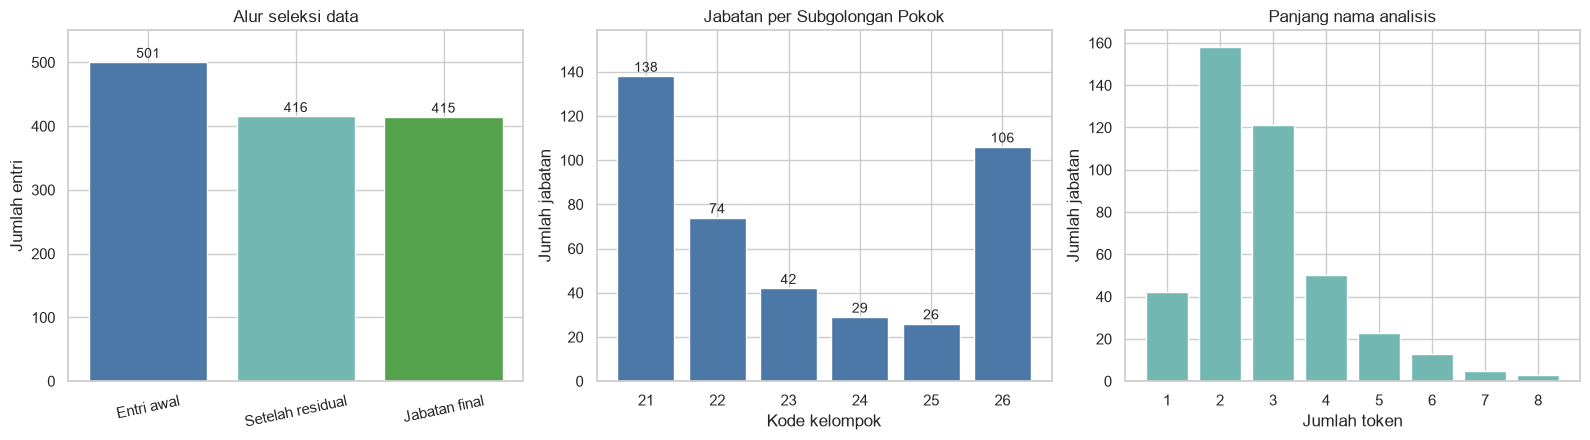

**Persiapan:** 501 − 85 residual − 1 leakage = 415 jabatan. Satu token: 42; multikata: 373. Perbedaan jumlah kelompok diperhitungkan dalam proporsi.

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
flow_labels = ['Entri awal', 'Setelah residual', 'Jabatan final']
flow_values = [len(source), int((~source['residual_recomputed']).sum()), len(data)]
axes[0].bar(flow_labels, flow_values, color=['#4C78A8', '#72B7B2', '#54A24B'])
for i, n in enumerate(flow_values): axes[0].text(i, n + 6, str(n), ha='center')
axes[0].set(title='Alur seleksi data', ylabel='Jumlah entri', ylim=(0, 550))
axes[0].tick_params(axis='x', rotation=12)
axes[1].bar(counts.index, counts.values, color='#4C78A8')
for i, n in enumerate(counts): axes[1].text(i, n + 2, str(n), ha='center')
axes[1].set(title='Jabatan per Subgolongan Pokok', xlabel='Kode kelompok', ylabel='Jumlah jabatan', ylim=(0, counts.max() * 1.15))
token_counts = data['token_count'].value_counts().sort_index()
axes[2].bar(token_counts.index, token_counts.values, color='#72B7B2')
axes[2].set(title='Panjang nama analisis', xlabel='Jumlah token', ylabel='Jumlah jabatan')
finish_figure(fig, 'persiapan_data', f"**Persiapan:** {len(source)} − {source['residual_recomputed'].sum()} residual − {source['gender_leakage_recomputed'].sum()} leakage = {len(data)} jabatan. Satu token: {token_composition.iloc[0]['aktual']}; multikata: {token_composition.iloc[1]['aktual']}. Perbedaan jumlah kelompok diperhitungkan dalam proporsi.")

## 3. Provenance model, embedding, normalisasi L2, dan OOV

Identitas model dan seluruh input dihash secara streaming. Model statis resmi fastText Bahasa Indonesia menggunakan Common Crawl/Wikipedia, CBOW dengan bobot posisi, 300 dimensi ([dokumentasi resmi](https://fasttext.cc/docs/en/crawl-vectors.html)). File biner dapat membentuk vektor subkata untuk OOV. Model pembanding di repository tidak dimuat.

Menurut Persamaan (2.2)–(2.3), ambil vektor mentah tiap token (`float64` sebelum agregasi), rata-rata dengan koefisien sama, lalu normalisasi L2. Token tidak dinormalisasi sebelum dirata-ratakan. Representasi ini tidak menangkap urutan atau konteks; koefisien sama tidak menjamin pengaruh geometris sama karena panjang/arah vektor berbeda. OOV dicatat dan tidak dibuang.

In [5]:
t0 = time.perf_counter()
input_metadata = []
for key in ['data_path', 'raw_verification_path', 'lexicon_path', 'lexicon_historical_path', 'pdf_path', 'model_path']:
    path = ROOT / CONFIG[key]
    assert path.is_file(), f'Input tidak tersedia: {path}'
    input_metadata.append({'role': key, 'path': CONFIG[key], 'size_bytes': path.stat().st_size, 'sha256': sha256_file(path)})
TIMINGS['input_hash_seconds'] = time.perf_counter() - t0
display(pd.DataFrame(input_metadata))
t0 = time.perf_counter()
model = fasttext.load_model(str(ROOT / CONFIG['model_path']))
assert model.get_dimension() == 300
vocabulary_size = len(model.words)
TIMINGS['model_load_seconds'] = time.perf_counter() - t0
model_metadata = {'name': Path(CONFIG['model_path']).name, 'size_bytes': (ROOT / CONFIG['model_path']).stat().st_size,
    'dimension': model.get_dimension(), 'vocabulary_size': vocabulary_size,
    'sha256': next(x['sha256'] for x in input_metadata if x['role'] == 'model_path'),
    'source_url': CONFIG['model_source_url'], 'documentation_url': CONFIG['model_documentation_url'],
    'python_version': platform.python_version(), 'fasttext_community_version': VERSIONS['fasttext-community']}
print(model_metadata)

,role,path,size_bytes,sha256
0,data_path,data/test1_v5_kbji_profesional_clean.csv,134268,83e19246b8490ce0c1ff5b186b0ace7f4ed4130a5fe3d2...
1,raw_verification_path,data/test_v2_kbji_profesional_all.csv,157614,c0fd92dbd9db6a7a4b259f928bec99c91abd7faa5e3bc0...
2,lexicon_path,data/test_v2_istilah_gender.csv,1079,47a843ece93828d8bec59a2666fc414accf38a3c6dd66f...
3,lexicon_historical_path,data/test1_v5_gender_lexicon.csv,1876,6eea2db90065a64fcf958f9755adc6d776a781881dc91d...
4,pdf_path,data/KBJI 2014.pdf,34550550,a9831205cf1eaed796f85b29771169f52ce1c9c9a44c91...
5,model_path,models/cc.id.300.bin,7236808873,46e6e4c3975c2386f76c608c896cb36fa9c90f9d7f8212...


{'name': 'cc.id.300.bin', 'size_bytes': 7236808873, 'dimension': 300, 'vocabulary_size': 2000000, 'sha256': '46e6e4c3975c2386f76c608c896cb36fa9c90f9d7f8212988c7eeb5ff41d235f', 'source_url': 'https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.id.300.bin.gz', 'documentation_url': 'https://fasttext.cc/docs/en/crawl-vectors.html', 'python_version': '3.13.15', 'fasttext_community_version': '0.11.7'}


,token,in_vocabulary,dimension,raw_norm,finite,is_gender_attribute


,token,in_vocabulary,dimension,raw_norm,finite,is_gender_attribute
101,endodontist,False,300,1.0,True,False
299,paedodontist,False,300,1.0,True,False
405,prosthodontist,False,300,1.0,True,False
450,subtitler,False,300,1.0,True,False
490,unani,False,300,1.0,True,False


,attribute,gender,pair_id,in_vocabulary,raw_norm,unit_norm,finite
0,laki-laki,male,laki_laki_perempuan,True,1.0,1.0,True
1,pria,male,pria_wanita,True,1.0,1.0,True
2,ayah,male,ayah_ibu,True,1.0,1.0,True
3,suami,male,suami_istri,True,1.0,1.0,True
4,putra,male,putra_putri,True,1.0,1.0,True
5,pemuda,male,pemuda_pemudi,True,1.0,1.0,True
6,cowok,male,cowok_cewek,True,1.0,1.0,True
7,jejaka,male,jejaka_gadis,True,1.0,1.0,True
8,perempuan,female,laki_laki_perempuan,True,1.0,1.0,True
9,wanita,female,pria_wanita,True,1.0,1.0,True


,occupation_code,occupation_name_raw,occupation_text,token_count,submajor_group_code,oov_tokens,oov_token_count,has_oov,dimension,raw_norm,unit_norm,finite
170,2230.06,Praktisi Unani,praktisi unani,2,22,[unani],1,True,300,0.755101,1.0,True
183,2261.05,Endodontist,endodontist,1,22,[endodontist],1,True,300,1.000000,1.0,True
187,2261.09,Paedodontist,paedodontist,1,22,[paedodontist],1,True,300,1.000000,1.0,True
189,2261.11,Prosthodontist,prosthodontist,1,22,[prosthodontist],1,True,300,1.000000,1.0,True
376,2643.05,Subtitler,subtitler,1,26,[subtitler],1,True,300,1.000000,1.0,True


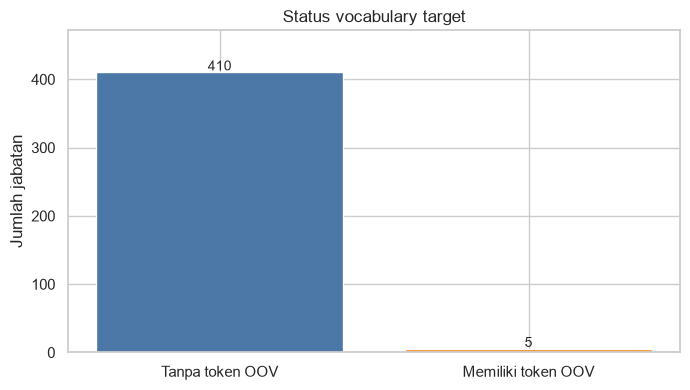

**OOV:** 5 dari 415 jabatan memiliki token OOV. Semua vektor target valid; fastText subword tetap digunakan dan OOV tidak diperlakukan sebagai kesalahan otomatis.

131

In [6]:
t0 = time.perf_counter()
unique_tokens = sorted(set(itertools.chain.from_iterable(data['tokens'])) | set(TERMS))
token_vectors = {token: np.asarray(model.get_word_vector(token), dtype=np.float64) for token in unique_tokens}
token_audit = pd.DataFrame([
    {'token': token, 'in_vocabulary': model.get_word_id(token) >= 0,
     'dimension': vector.size, 'raw_norm': float(np.linalg.norm(vector)),
     'finite': bool(np.isfinite(vector).all()), 'is_gender_attribute': token in TERMS}
    for token, vector in token_vectors.items()])
bad_tokens = token_audit.loc[~token_audit['finite'] | token_audit['raw_norm'].le(0) | token_audit['dimension'].ne(300)]
display(bad_tokens)
assert bad_tokens.empty, 'Vektor token tidak valid; identitas ditampilkan, tidak diganti nol.'
target_raw = np.stack([np.stack([token_vectors[token] for token in tokens]).mean(axis=0) for tokens in data['tokens']])
target_norms = np.linalg.norm(target_raw, axis=1)
attribute_raw = np.stack([token_vectors[term] for term in TERMS])
attribute_norms = np.linalg.norm(attribute_raw, axis=1)
assert np.isfinite(target_raw).all() and np.all(target_norms > 0)
targets = target_raw / target_norms[:, None]
attributes = attribute_raw / attribute_norms[:, None]
token_vocab = token_audit.set_index('token')['in_vocabulary'].to_dict()
data['oov_tokens'] = data['tokens'].map(lambda tokens: [token for token in tokens if not token_vocab[token]])
data['oov_token_count'] = data['oov_tokens'].str.len()
data['has_oov'] = data['oov_token_count'].gt(0)
audit_vektor = data[['occupation_code', 'occupation_name_raw', 'occupation_text', 'token_count',
    'submajor_group_code', 'oov_tokens', 'oov_token_count', 'has_oov']].copy()
audit_vektor['dimension'] = targets.shape[1]
audit_vektor['raw_norm'] = target_norms
audit_vektor['unit_norm'] = np.linalg.norm(targets, axis=1)
audit_vektor['finite'] = np.isfinite(targets).all(axis=1)
attribute_audit = pd.DataFrame({'attribute': TERMS, 'gender': ['male'] * 8 + ['female'] * 8,
    'pair_id': PAIR_ORDER * 2, 'in_vocabulary': [token_vocab[t] for t in TERMS],
    'raw_norm': attribute_norms, 'unit_norm': np.linalg.norm(attributes, axis=1),
    'finite': np.isfinite(attributes).all(axis=1)})
assert np.allclose(audit_vektor['unit_norm'], 1, atol=CONFIG['atol'], rtol=CONFIG['rtol'])
assert np.allclose(attribute_audit['unit_norm'], 1, atol=CONFIG['atol'], rtol=CONFIG['rtol'])
TIMINGS['embedding_seconds'] = time.perf_counter() - t0
CHECKS.append({'check': 'Vektor 300 dimensi finite dan norma satu', 'observed': str(targets.shape),
    'expected': '415 × 300; 16 × 300', 'status': True, 'notes': 'Vektor token/target/atribut dicek sebelum dan setelah normalisasi.'})
display(token_audit.loc[~token_audit['in_vocabulary']])
display(attribute_audit)
display(audit_vektor.loc[audit_vektor['has_oov']].head(20))
fig, ax = plt.subplots(figsize=(7, 4))
oov_counts = [int((~data['has_oov']).sum()), int(data['has_oov'].sum())]
ax.bar(['Tanpa token OOV', 'Memiliki token OOV'], oov_counts, color=['#4C78A8', '#F58518'])
for i, n in enumerate(oov_counts): ax.text(i, n + 3, str(n), ha='center')
ax.set(title='Status vocabulary target', ylabel='Jumlah jabatan', ylim=(0, max(oov_counts) * 1.15))
finish_figure(fig, 'audit_oov', f"**OOV:** {oov_counts[1]} dari {len(data)} jabatan memiliki token OOV. Semua vektor target valid; fastText subword tetap digunakan dan OOV tidak diperlakukan sebagai kesalahan otomatis.")
del model
import gc
gc.collect()

## 4. Cosine, SC-WEAT, permutasi eksak, dan BH-FDR — RM 1

Cosine (Persamaan 2.4) adalah hasil kali titik vektor satuan. Untuk satu jabatan, SC-WEAT (2.8) memakai:

\[
d(w)=\frac{\overline{\cos(w,M)}-\overline{\cos(w,F)}}{\mathrm{std}(\{\cos(w,a):a\in M\cup F\},\mathrm{ddof}=0)}.
\]

Penyebut merupakan penyebaran 16 cosine **pada satu jabatan**, bukan penyebaran antarjabatan atau standard error. Positif berarti relatif lebih dekat ke laki-laki, negatif ke perempuan, nol tepat pada skor nol.

Statistik (2.9) adalah selisih jumlah `T=8×association_difference`. Seluruh `C(16,8)=12.870` pembagian berlabel dienumerasi (bukan pertukaran terbatas dalam pasangan). P-value eksak dua sisi (2.10) menghitung `|T_perm| ≥ |T_obs|`, termasuk ties, pengamatan dan komplemennya, dengan toleransi tetap `atol=rtol=1e-12`. Tidak ada koreksi tambah satu. BH (2.11) diterapkan sekali pada seluruh 415 jabatan. Persamaan (2.5)–(2.7) adalah latar WEAT, bukan pengganti pengukuran target tunggal.

In [7]:
t0 = time.perf_counter()
cosines = targets @ attributes.T
assert cosines.shape == (415, 16) and np.isfinite(cosines).all()
assert np.max(np.abs(cosines)) <= 1 + CONFIG['atol']
partitions = np.array(list(itertools.combinations(range(16), 8)), dtype=np.int16)
permutation_signs = np.full((len(partitions), 16), -1.0, dtype=np.float64)
permutation_signs[np.arange(len(partitions))[:, None], partitions] = 1.0
assert len(partitions) == 12870 and len(np.unique(partitions, axis=0)) == 12870
assert np.all(permutation_signs.sum(axis=1) == 0)

def measure_scweat(cosine_values, male_indices, female_indices, signs, atol, rtol, q):
    """Hitung target tunggal ddof=0, exact two-sided p, dan BH satu keluarga."""
    denominator = np.std(cosine_values, axis=1, ddof=0)
    assert np.all(denominator > 0), 'Penyebut nol: skor tidak terdefinisi.'
    male_mean = cosine_values[:, male_indices].mean(axis=1)
    female_mean = cosine_values[:, female_indices].mean(axis=1)
    difference = male_mean - female_mean
    observed_signs = np.full(cosine_values.shape[1], -1.0)
    observed_signs[male_indices] = 1.0
    observed_index = np.flatnonzero(np.all(signs == observed_signs, axis=1)).item()
    permutation_statistics = cosine_values @ signs.T
    observed = permutation_statistics[:, observed_index]
    threshold = np.abs(observed)[:, None]
    extreme = ((np.abs(permutation_statistics) >= threshold) |
               np.isclose(np.abs(permutation_statistics), threshold, atol=atol, rtol=rtol)).sum(axis=1)
    p_raw = extreme / len(signs)
    reject, adjusted, _, _ = multipletests(p_raw, alpha=q, method='fdr_bh')
    return {'mean_cosine_male': male_mean, 'mean_cosine_female': female_mean,
            'association_difference': difference, 'std_cosine_all': denominator,
            'effect_size': difference / denominator, 'T_observed': observed,
            'extreme_count': extreme, 'p_raw': p_raw, 'p_adjusted': adjusted, 'reject_fdr': reject}

male_indices, female_indices = np.arange(8), np.arange(8, 16)
measurements = measure_scweat(cosines, male_indices, female_indices, permutation_signs,
                            CONFIG['atol'], CONFIG['rtol'], CONFIG['fdr_q'])
identity_columns = ['occupation_code', 'occupation_name_raw', 'occupation_text', 'submajor_group_code', 'submajor_group_name']
results = pd.concat([data[identity_columns], pd.DataFrame(measurements)], axis=1)
results['direction'] = np.select([results['effect_size'] > CONFIG['zero_atol'],
                                  results['effect_size'] < -CONFIG['zero_atol']], ['positif', 'negatif'], default='nol')
results['rank_baseline'] = results['effect_size'].rank(ascending=False, method='average')
results['reject_raw'] = results['p_raw'] <= CONFIG['fdr_q']
cosine_table = pd.concat([data[['occupation_code']], pd.DataFrame(cosines, columns=['cosine_' + t for t in TERMS])], axis=1)
assert np.allclose(results['T_observed'], 8 * results['association_difference'], atol=CONFIG['atol'], rtol=CONFIG['rtol'])
TIMINGS['main_scweat_seconds'] = time.perf_counter() - t0
display(results.head(10))
display(results['direction'].value_counts().reindex(['positif', 'negatif', 'nol'], fill_value=0).rename('jumlah').to_frame())
print({'jumlah_permutasi': len(partitions), 'raw_significant': int(results['reject_raw'].sum()),
       'BH_global_significant': int(results['reject_fdr'].sum())})

,occupation_code,occupation_name_raw,occupation_text,submajor_group_code,submajor_group_name,mean_cosine_male,mean_cosine_female,association_difference,std_cosine_all,effect_size,T_observed,extreme_count,p_raw,p_adjusted,reject_fdr,direction,rank_baseline,reject_raw
0,2111.01,Ahli Fisika (Umum),ahli fisika umum,21,Ahli ilmu pengetahuan dan teknik,0.316802,0.318424,-0.001621,0.051489,-0.031490,-0.012971,12300,0.955711,0.999223,False,negatif,127.0,False
1,2111.02,Ahli Fisika Nuklir,ahli fisika nuklir,21,Ahli ilmu pengetahuan dan teknik,0.268074,0.273548,-0.005474,0.040390,-0.135537,-0.043795,10358,0.804817,0.999223,False,negatif,194.0,False
2,2111.03,Ahli Fisika Mekanika,ahli fisika mekanika,21,Ahli ilmu pengetahuan dan teknik,0.254108,0.245780,0.008328,0.036730,0.226744,0.066627,8636,0.671018,0.999223,False,positif,24.0,False
3,2111.04,Ahli Fisika Panas,ahli fisika panas,21,Ahli ilmu pengetahuan dan teknik,0.301160,0.300744,0.000416,0.046534,0.008941,0.003329,12694,0.986325,0.999223,False,positif,99.0,False
4,2111.05,Ahli Fisika Sinar,ahli fisika sinar,21,Ahli ilmu pengetahuan dan teknik,0.296322,0.282230,0.014092,0.040652,0.346651,0.112737,6652,0.516861,0.999223,False,positif,8.0,False
5,2111.06,Ahli Fisika Suara,ahli fisika suara,21,Ahli ilmu pengetahuan dan teknik,0.323985,0.314031,0.009954,0.047431,0.209854,0.079629,8916,0.692774,0.999223,False,positif,29.0,False
6,2111.07,Ahli Fisika Listrik Dan Magnit,ahli fisika listrik dan magnit,21,Ahli ilmu pengetahuan dan teknik,0.322693,0.316286,0.006407,0.045983,0.139335,0.051256,10248,0.796270,0.999223,False,positif,47.0,False
7,2111.08,Ahli Fisika Elektronika,ahli fisika elektronika,21,Ahli ilmu pengetahuan dan teknik,0.265504,0.270569,-0.005065,0.039014,-0.129835,-0.040523,10438,0.811033,0.999223,False,negatif,190.0,False
8,2111.09,Ahli Fisika Medis,ahli fisika medis,21,Ahli ilmu pengetahuan dan teknik,0.299432,0.300342,-0.000910,0.052157,-0.017448,-0.007280,12540,0.974359,0.999223,False,negatif,120.0,False
9,2111.10,Ahli Astronomi,ahli astronomi,21,Ahli ilmu pengetahuan dan teknik,0.272423,0.264427,0.007995,0.048711,0.164137,0.063963,9770,0.759130,0.999223,False,positif,39.0,False


,jumlah
direction,
positif,105
negatif,310
nol,0


{'jumlah_permutasi': 12870, 'raw_significant': 0, 'BH_global_significant': 0}


### Distribusi dan jabatan dengan skor ekstrem — RM 1

Histogram memperlihatkan sebaran 415 skor, sedangkan dot plot memilih maksimal 15 skor positif terbesar dan 15 skor negatif terkecil, berdasarkan nilai bertanda belum dibulatkan. Nama dan kode tetap disertakan; skor ekstrem tidak otomatis signifikan.

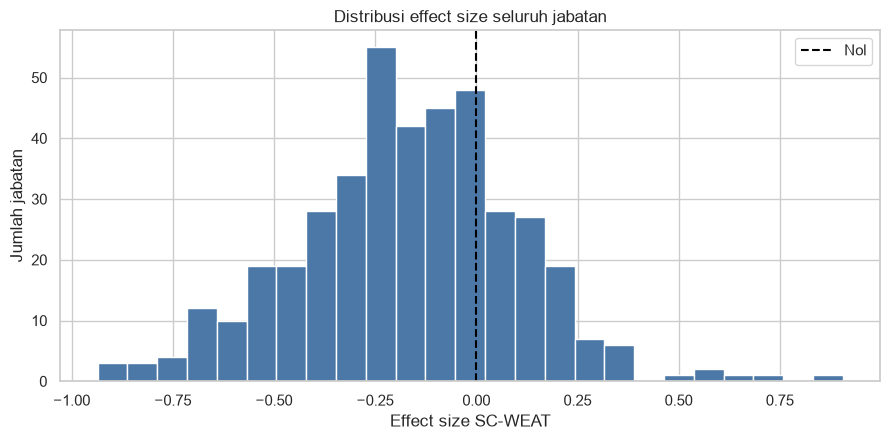

**RM 1:** rata-rata -0.1700, median -0.1676, rentang -0.9359 hingga 0.9055 pada 415 jabatan.

,occupation_code,occupation_name_raw,effect_size,p_adjusted,reject_fdr
230,2320.02,Instruktur Tata Rias,-0.935940,0.999223,False
390,2653.02,Penari Balet,-0.902061,0.999223,False
162,2221.05,Perawat,-0.882596,0.999223,False
137,2166.10,Desainer Website,-0.841080,0.999223,False
248,2355.01,Guru Tari,-0.817205,0.999223,False
135,2166.08,Desainer Multimedia,-0.794506,0.999223,False
292,2513.03,Pengembang Internet,-0.781407,0.999223,False
164,2222.01,Bidan,-0.748030,0.999223,False
163,2221.06,Perawat Anastesi,-0.727175,0.999223,False
287,2512.02,Desainer Software,-0.723900,0.999223,False


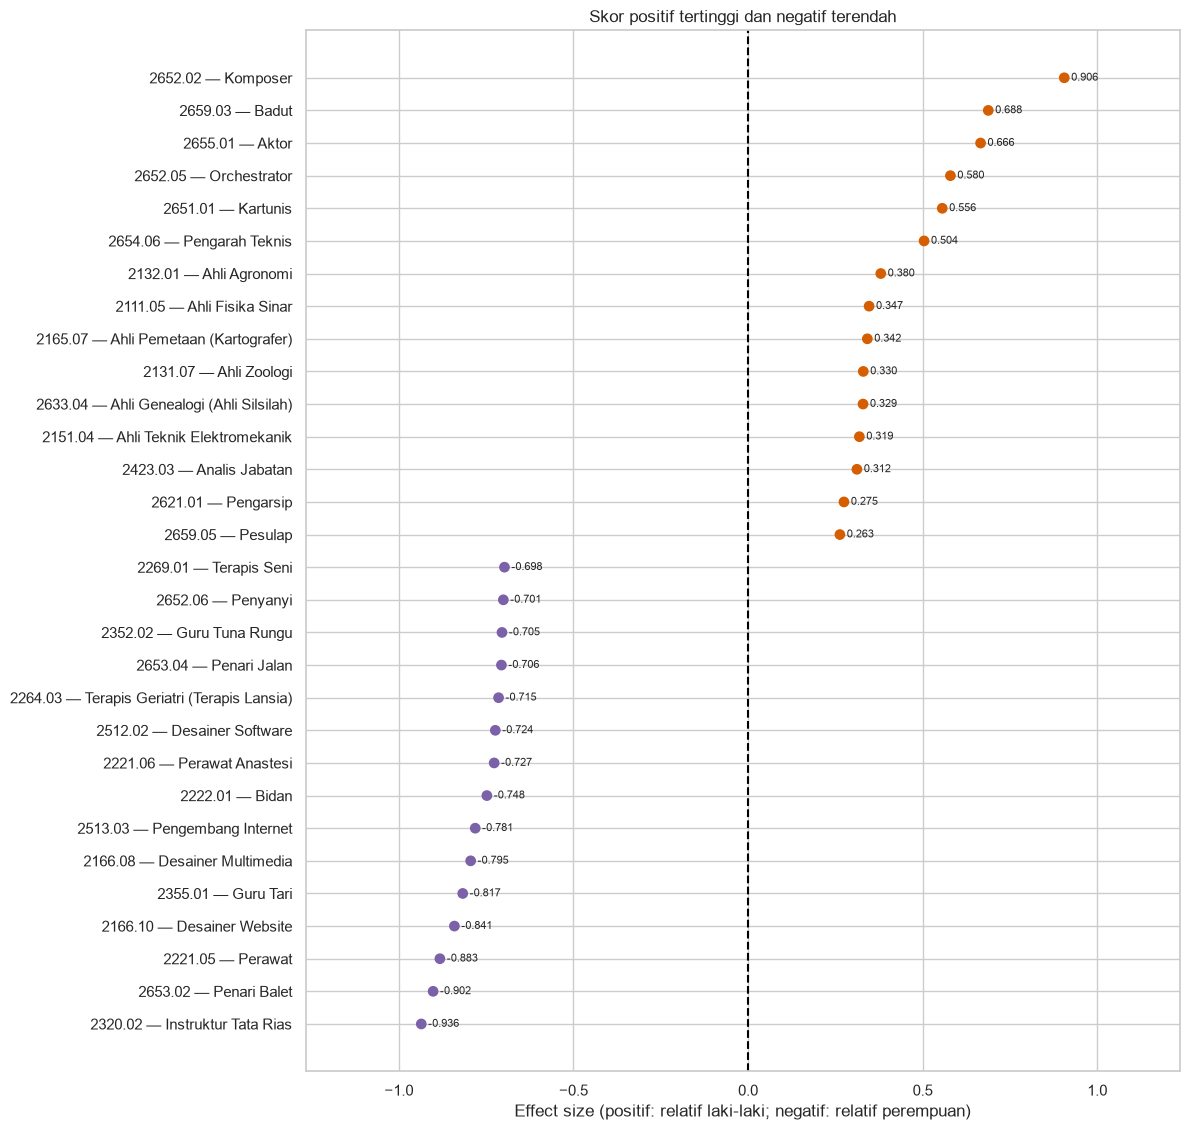

**Pemilihan:** 15 skor positif terbesar dan 15 skor negatif terkecil, diurutkan dari skor terkecil ke terbesar. Signifikansi pada tabel menggunakan BH global.

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(results['effect_size'], bins=25, color='#4C78A8', edgecolor='white')
ax.axvline(0, color='black', linestyle='--', label='Nol')
ax.set(title='Distribusi effect size seluruh jabatan', xlabel='Effect size SC-WEAT', ylabel='Jumlah jabatan')
ax.legend()
finish_figure(fig, 'rm1_histogram_effect_size', f"**RM 1:** rata-rata {results['effect_size'].mean():.4f}, median {results['effect_size'].median():.4f}, rentang {results['effect_size'].min():.4f} hingga {results['effect_size'].max():.4f} pada {len(results)} jabatan.")

extreme_jobs = pd.concat([
    results.loc[results['direction'].eq('positif')].nlargest(CONFIG['top_n_each_direction'], 'effect_size'),
    results.loc[results['direction'].eq('negatif')].nsmallest(CONFIG['top_n_each_direction'], 'effect_size')]).sort_values('effect_size')
display(extreme_jobs[['occupation_code', 'occupation_name_raw', 'effect_size', 'p_adjusted', 'reject_fdr']])
fig, ax = plt.subplots(figsize=(12, max(5, len(extreme_jobs) * 0.38)))
labels = [fill(f'{row.occupation_code} — {row.occupation_name_raw}', 57) for row in extreme_jobs.itertuples()]
ax.scatter(extreme_jobs['effect_size'], np.arange(len(extreme_jobs)),
           c=extreme_jobs['direction'].map(PALETTE), s=45)
for i, value in enumerate(extreme_jobs['effect_size']):
    ax.annotate(f'{value:.3f}', (value, i), xytext=(5, 0), textcoords='offset points', va='center', fontsize=8)
ax.set_yticks(np.arange(len(extreme_jobs)), labels=labels)
ax.axvline(0, color='black', linestyle='--')
ax.margins(x=0.18)
ax.set(title='Skor positif tertinggi dan negatif terendah', xlabel='Effect size (positif: relatif laki-laki; negatif: relatif perempuan)')
finish_figure(fig, 'rm1_jabatan_ekstrem', f"**Pemilihan:** {sum(extreme_jobs['direction'].eq('positif'))} skor positif terbesar dan {sum(extreme_jobs['direction'].eq('negatif'))} skor negatif terkecil, diurutkan dari skor terkecil ke terbesar. Signifikansi pada tabel menggunakan BH global.")

### Cosine dan pengujian berganda — RM 1

Scatter cosine memakai skala x/y sama dan garis kesamaan. P-value terurut disandingkan dengan garis ambang BH `q·i/415`. Grafik adjusted p-value memisahkan besar effect size dari keputusan statistik. Tidak signifikan tidak berarti tidak ada asosiasi.

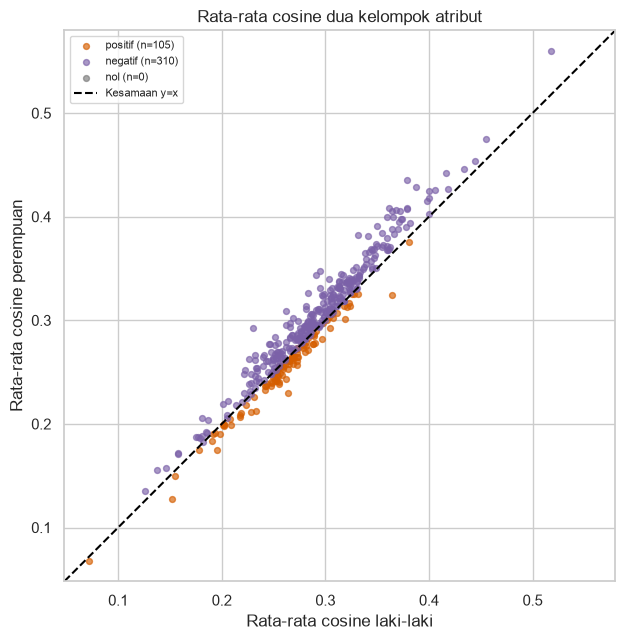

**Cosine:** 105 jabatan di sisi relatif laki-laki, 310 di sisi relatif perempuan, dan 0 nol; arah tidak menyatakan kelayakan gender pekerjaan.

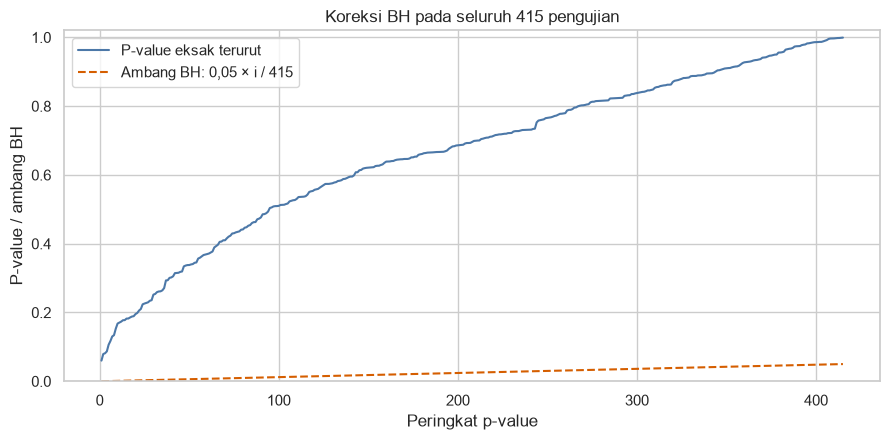

**BH global:** p mentah minimum 0.060140; 0 hasil mentah ≤ 0,05, dan 0 ditolak setelah BH global. Pengujian dua sisi tetap mencakup ties dan komplemen.

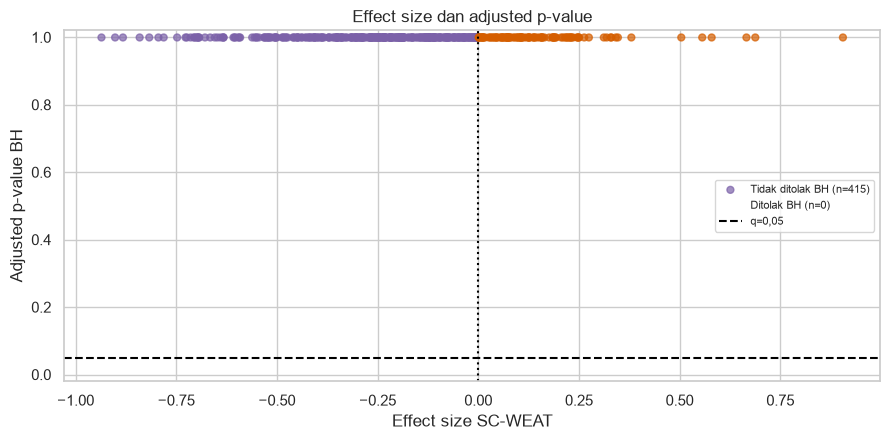

**Signifikansi:** 0 dari 415 hasil melewati keputusan BH global. Besar skor dan signifikansi dibaca terpisah; hasil tidak signifikan tetap memiliki arah dan effect size terukur.

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for direction in ['positif', 'negatif', 'nol']:
    subset = results.loc[results['direction'].eq(direction)]
    ax.scatter(subset['mean_cosine_male'], subset['mean_cosine_female'], color=PALETTE[direction],
               s=18, alpha=0.65, label=f'{direction} (n={len(subset)})')
limits = [results[['mean_cosine_male', 'mean_cosine_female']].to_numpy().min() - 0.02,
          results[['mean_cosine_male', 'mean_cosine_female']].to_numpy().max() + 0.02]
ax.plot(limits, limits, '--', color='black', label='Kesamaan y=x')
ax.set(xlim=limits, ylim=limits, aspect='equal', title='Rata-rata cosine dua kelompok atribut',
       xlabel='Rata-rata cosine laki-laki', ylabel='Rata-rata cosine perempuan')
ax.legend(fontsize=8)
finish_figure(fig, 'rm1_cosine_male_female', f"**Cosine:** {sum(results['direction'].eq('positif'))} jabatan di sisi relatif laki-laki, {sum(results['direction'].eq('negatif'))} di sisi relatif perempuan, dan {sum(results['direction'].eq('nol'))} nol; arah tidak menyatakan kelayakan gender pekerjaan.")

ordered_p = np.sort(results['p_raw'].to_numpy())
bh_ranks = np.arange(1, len(results) + 1)
bh_threshold = CONFIG['fdr_q'] * bh_ranks / len(results)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(bh_ranks, ordered_p, label='P-value eksak terurut', color='#4C78A8')
ax.plot(bh_ranks, bh_threshold, '--', label='Ambang BH: 0,05 × i / 415', color='#D55E00')
ax.set(title='Koreksi BH pada seluruh 415 pengujian', xlabel='Peringkat p-value', ylabel='P-value / ambang BH', ylim=(0, 1.02))
ax.legend()
finish_figure(fig, 'rm1_pvalue_bh', f"**BH global:** p mentah minimum {ordered_p.min():.6f}; {results['reject_raw'].sum()} hasil mentah ≤ 0,05, dan {results['reject_fdr'].sum()} ditolak setelah BH global. Pengujian dua sisi tetap mencakup ties dan komplemen.")

fig, ax = plt.subplots(figsize=(9, 4.5))
for rejected, marker, label in [(False, 'o', 'Tidak ditolak BH'), (True, 'X', 'Ditolak BH')]:
    subset = results.loc[results['reject_fdr'].eq(rejected)]
    ax.scatter(subset['effect_size'], subset['p_adjusted'], marker=marker, s=25,
               c=subset['direction'].map(PALETTE), alpha=0.7, label=f'{label} (n={len(subset)})')
ax.axhline(CONFIG['fdr_q'], linestyle='--', color='black', label='q=0,05')
ax.axvline(0, linestyle=':', color='black')
ax.set(title='Effect size dan adjusted p-value', xlabel='Effect size SC-WEAT', ylabel='Adjusted p-value BH', ylim=(-0.02, 1.02))
ax.legend(fontsize=8)
finish_figure(fig, 'rm1_effect_size_adjusted_pvalue', f"**Signifikansi:** {results['reject_fdr'].sum()} dari {len(results)} hasil melewati keputusan BH global. Besar skor dan signifikansi dibaca terpisah; hasil tidak signifikan tetap memiliki arah dan effect size terukur.")

## 5. Perbandingan deskriptif enam Subgolongan Pokok — RM 2

Setiap statistik dihitung dari skor individual anggota kelompok. Simpangan baku `ddof=0` di sini menggambarkan penyebaran **antarjabatan**, berbeda dari penyebut SC-WEAT. Jumlah/proporsi signifikan mengambil keputusan BH keluarga global yang sudah dihitung; tidak ada pengujian baru, ANOVA, Kruskal-Wallis, atau klaim beda signifikan kelompok.

In [10]:
group_rows = []
for group_code in CONFIG['group_order']:
    subset = results.loc[results['submajor_group_code'].eq(group_code)]
    values = subset['effect_size'].to_numpy()
    row = {'submajor_group_code': group_code, 'submajor_group_name': GROUP_NAMES[group_code],
           'n_occupations': len(subset), 'mean_effect_size': values.mean(),
           'median_effect_size': np.median(values), 'std_effect_size': values.std(ddof=0),
           'min_effect_size': values.min(), 'max_effect_size': values.max(),
           'n_significant_fdr': int(subset['reject_fdr'].sum()),
           'proportion_significant_fdr': subset['reject_fdr'].mean()}
    for direction in ['positif', 'negatif', 'nol']:
        row['n_' + direction] = int(subset['direction'].eq(direction).sum())
        row['proportion_' + direction] = subset['direction'].eq(direction).mean()
    group_rows.append(row)
group_summary = pd.DataFrame(group_rows)
assert group_summary['n_occupations'].sum() == len(results)
assert np.allclose(group_summary[['proportion_positif', 'proportion_negatif', 'proportion_nol']].sum(axis=1), 1)
assert group_summary['n_significant_fdr'].sum() == results['reject_fdr'].sum()
display(group_summary)
GROUP_LABELS = [fill(f"{row.submajor_group_code} — {row.submajor_group_name} (n={row.n_occupations})", 45)
                for row in group_summary.itertuples()]

,submajor_group_code,submajor_group_name,n_occupations,mean_effect_size,median_effect_size,std_effect_size,min_effect_size,max_effect_size,n_significant_fdr,proportion_significant_fdr,n_positif,proportion_positif,n_negatif,proportion_negatif,n_nol,proportion_nol
0,21,Ahli Ilmu Pengetahuan dan Teknik,138,-0.100979,-0.076660,0.235006,-0.841080,0.380083,0,0.0,43,0.311594,95,0.688406,0,0.0
1,22,Profesional Kesehatan,74,-0.243296,-0.219313,0.255002,-0.882596,0.245482,0,0.0,13,0.175676,61,0.824324,0,0.0
2,23,Profesional Pendidikan,42,-0.341921,-0.321120,0.206298,-0.935940,0.044827,0,0.0,2,0.047619,40,0.952381,0,0.0
3,24,Profesional Bisnis dan Administrasi,29,-0.156908,-0.120311,0.234206,-0.605396,0.311660,0,0.0,7,0.241379,22,0.758621,0,0.0
4,25,Profesional Teknologi Informasi dan Komunikasi,26,-0.268795,-0.191301,0.251153,-0.781407,0.137853,0,0.0,3,0.115385,23,0.884615,0,0.0
5,26,"Profesional Hukum, Sosial, dan Budaya",106,-0.119927,-0.165963,0.312722,-0.902061,0.905523,0,0.0,37,0.349057,69,0.650943,0,0.0


### Penyebaran, pemusatan, dan proporsi arah

Boxplot ditambah seluruh titik individual; jitter memakai seed 42 dan hanya menggeser posisi tampilan pada sumbu kelompok. Diagram pemusatan membandingkan mean/median. Proporsi arah menggunakan jumlah anggota masing-masing kelompok sebagai denominator.

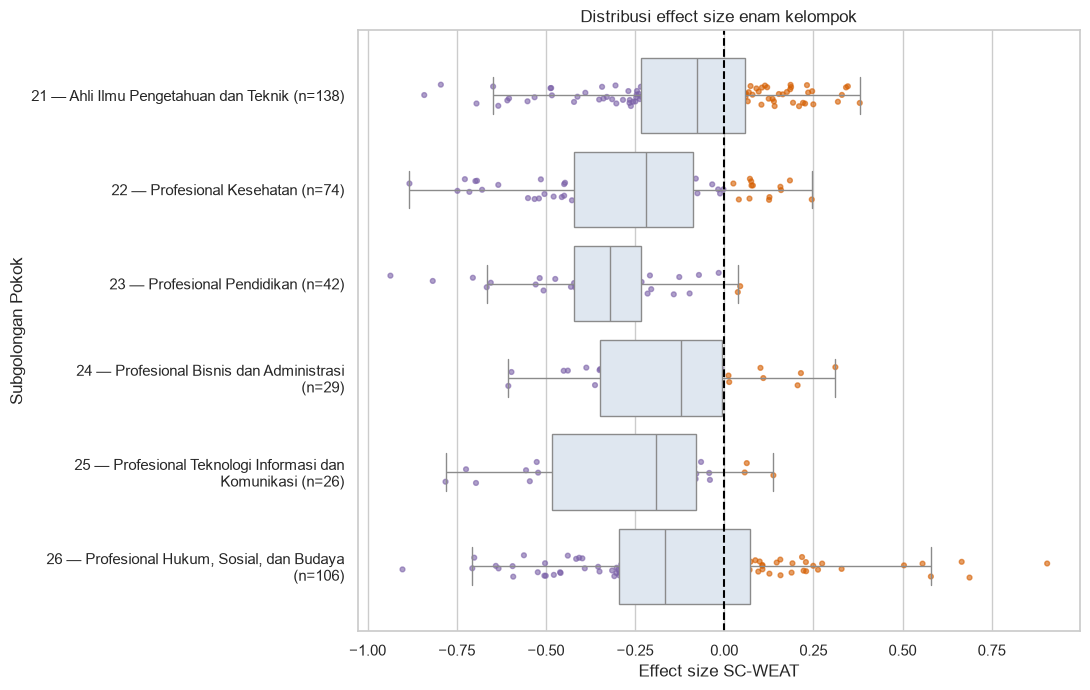

**RM 2:** seluruh 415 jabatan ditampilkan. Simpangan baku kelompok berkisar 0.2063–0.3127; boxplot menunjukkan variasi internal, bukan hasil uji beda kelompok.

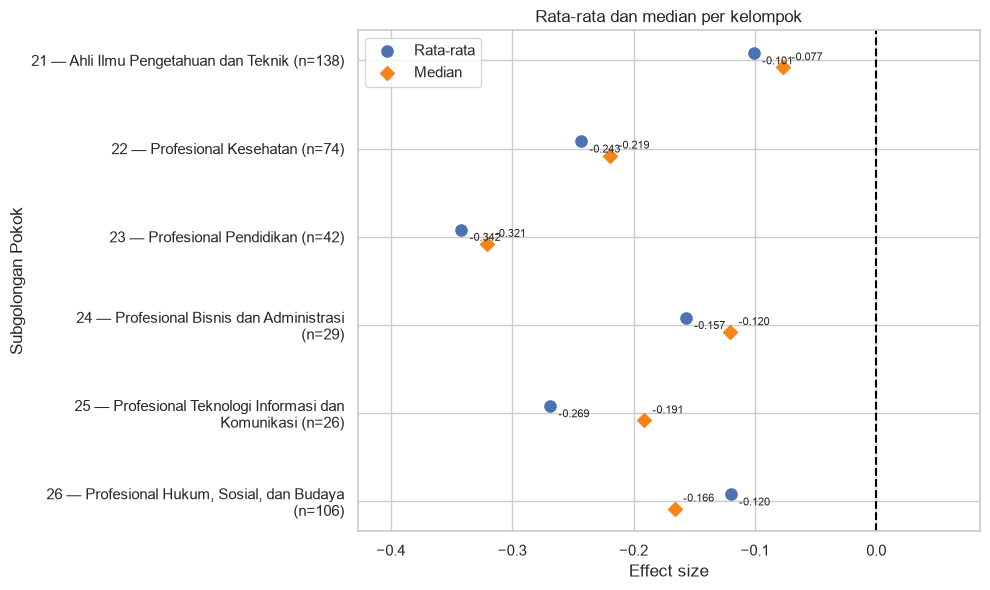

**Pemusatan:** rata-rata terendah kelompok 23 (-0.3419); tertinggi kelompok 21 (-0.1010). Perbandingan ini deskriptif.

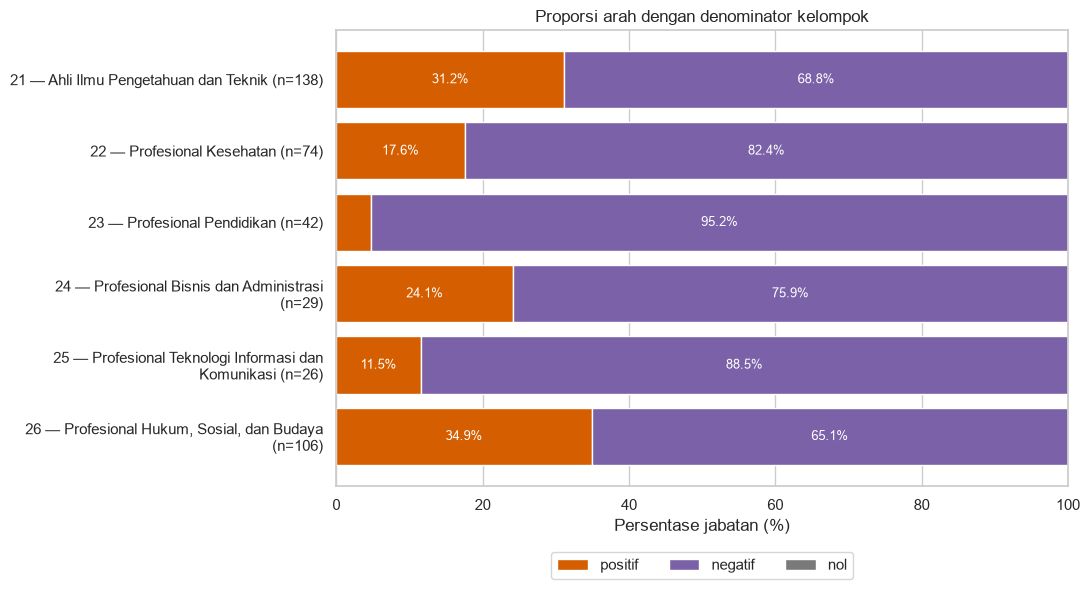

**Proporsi:** setiap bar memakai jumlah kelompok (138, 74, 42, 29, 26, 106) sebagai denominator dan berjumlah 100%. Jumlah skor nol seluruh data: 0.

In [11]:
fig, ax = plt.subplots(figsize=(11, 7))
sns.boxplot(data=results, x='effect_size', y='submajor_group_code', order=CONFIG['group_order'],
            color='#DCE7F3', showfliers=False, ax=ax)
plot_rng = np.random.default_rng(RANDOM_SEED)
for i, group_code in enumerate(CONFIG['group_order']):
    subset = results.loc[results['submajor_group_code'].eq(group_code)]
    positions = i + plot_rng.uniform(-CONFIG['jitter_width'], CONFIG['jitter_width'], len(subset))
    ax.scatter(subset['effect_size'], positions, c=subset['direction'].map(PALETTE), s=12, alpha=0.6)
ax.set_yticks(range(6), labels=GROUP_LABELS)
ax.axvline(0, linestyle='--', color='black')
ax.set(title='Distribusi effect size enam kelompok', xlabel='Effect size SC-WEAT', ylabel='Subgolongan Pokok')
finish_figure(fig, 'rm2_boxplot_observasi', f"**RM 2:** seluruh {len(results)} jabatan ditampilkan. Simpangan baku kelompok berkisar {group_summary['std_effect_size'].min():.4f}–{group_summary['std_effect_size'].max():.4f}; boxplot menunjukkan variasi internal, bukan hasil uji beda kelompok.")

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(group_summary['mean_effect_size'], np.arange(6) - 0.08, marker='o', s=65, label='Rata-rata')
ax.scatter(group_summary['median_effect_size'], np.arange(6) + 0.08, marker='D', s=50, label='Median', color='#F58518')
for i, row in enumerate(group_summary.itertuples()):
    ax.annotate(f'{row.mean_effect_size:.3f}', (row.mean_effect_size, i - 0.08), xytext=(6, -8), textcoords='offset points', fontsize=8)
    ax.annotate(f'{row.median_effect_size:.3f}', (row.median_effect_size, i + 0.08), xytext=(6, 5), textcoords='offset points', fontsize=8)
ax.set_yticks(range(6), labels=GROUP_LABELS)
ax.invert_yaxis()
ax.axvline(0, linestyle='--', color='black')
ax.set(title='Rata-rata dan median per kelompok', xlabel='Effect size', ylabel='Subgolongan Pokok')
ax.margins(x=0.25)
ax.legend()
finish_figure(fig, 'rm2_mean_median', f"**Pemusatan:** rata-rata terendah kelompok {group_summary.loc[group_summary['mean_effect_size'].idxmin(), 'submajor_group_code']} ({group_summary['mean_effect_size'].min():.4f}); tertinggi kelompok {group_summary.loc[group_summary['mean_effect_size'].idxmax(), 'submajor_group_code']} ({group_summary['mean_effect_size'].max():.4f}). Perbandingan ini deskriptif.")

fig, ax = plt.subplots(figsize=(11, 6))
left = np.zeros(6)
for direction in ['positif', 'negatif', 'nol']:
    proportions = group_summary['proportion_' + direction].to_numpy() * 100
    ax.barh(np.arange(6), proportions, left=left, color=PALETTE[direction], label=direction)
    for i, (start, proportion) in enumerate(zip(left, proportions)):
        if proportion > 5: ax.text(start + proportion / 2, i, f'{proportion:.1f}%', ha='center', va='center', color='white', fontsize=9)
    left += proportions
ax.set_yticks(range(6), labels=GROUP_LABELS)
ax.invert_yaxis()
ax.set(title='Proporsi arah dengan denominator kelompok', xlabel='Persentase jabatan (%)', xlim=(0, 100))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3)
finish_figure(fig, 'rm2_proporsi_arah', f"**Proporsi:** setiap bar memakai jumlah kelompok ({', '.join(str(x) for x in group_summary['n_occupations'])}) sebagai denominator dan berjumlah 100%. Jumlah skor nol seluruh data: {group_summary['n_nol'].sum()}.")

### ECDF dan keputusan FDR global

ECDF memperlihatkan distribusi tanpa pilihan lebar bin. Ringkasan signifikansi tetap ditampilkan walau jumlahnya nol; denominator masing-masing kelompok dan asal keputusan global dinyatakan.

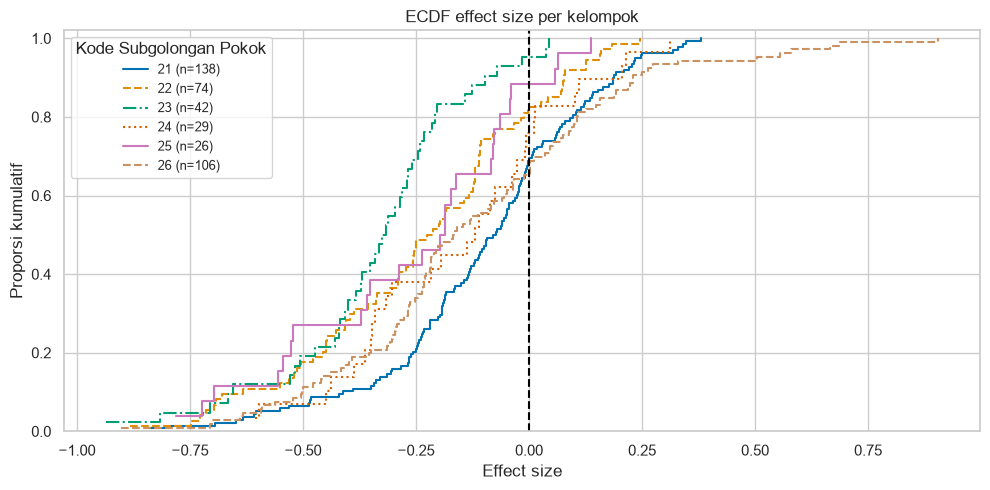

**ECDF:** enam distribusi berasal dari 415 skor individual. Rentang minimum–maksimum tiap kelompok tersedia pada ringkasan; bentuk kurva tidak ditafsirkan sebagai beda signifikan.

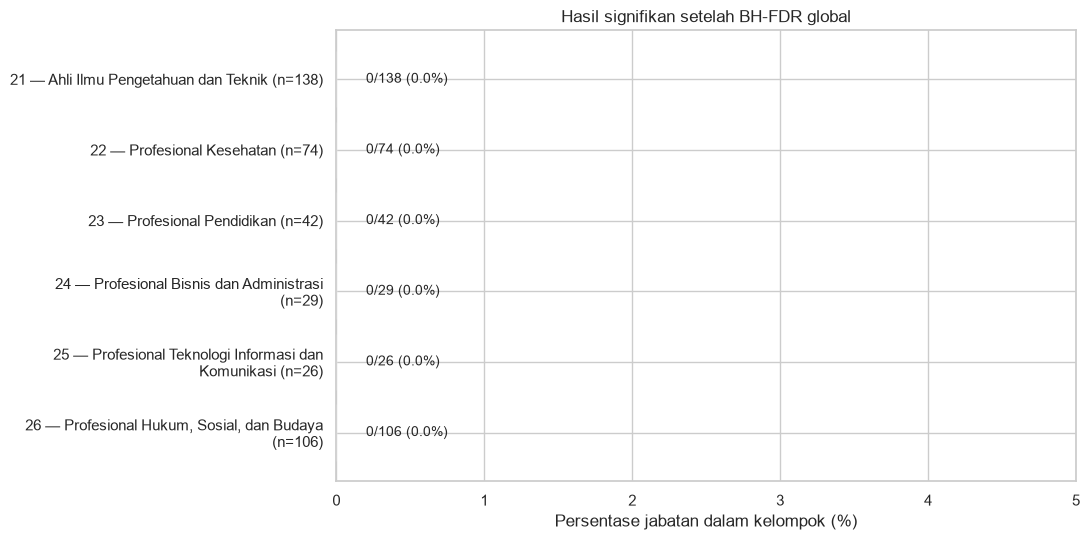

**FDR:** total 0 hasil signifikan dari keluarga global 415 pengujian. Nol signifikan tidak berarti semua skor nol atau tidak ada asosiasi intrinsik.

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
group_colors = sns.color_palette('colorblind', 6)
for i, group_code in enumerate(CONFIG['group_order']):
    values = np.sort(results.loc[results['submajor_group_code'].eq(group_code), 'effect_size'].to_numpy())
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where='post',
            color=group_colors[i], linestyle=['-', '--', '-.', ':', '-', '--'][i], label=f'{group_code} (n={len(values)})')
ax.axvline(0, color='black', linestyle='--')
ax.set(title='ECDF effect size per kelompok', xlabel='Effect size', ylabel='Proporsi kumulatif', ylim=(0, 1.02))
ax.legend(title='Kode Subgolongan Pokok', fontsize=9)
finish_figure(fig, 'rm2_ecdf', f"**ECDF:** enam distribusi berasal dari {len(results)} skor individual. Rentang minimum–maksimum tiap kelompok tersedia pada ringkasan; bentuk kurva tidak ditafsirkan sebagai beda signifikan.")

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(np.arange(6), group_summary['proportion_significant_fdr'] * 100, color='#54A24B')
for i, row in enumerate(group_summary.itertuples()):
    ax.text(row.proportion_significant_fdr * 100 + 0.2, i,
            f'{row.n_significant_fdr}/{row.n_occupations} ({row.proportion_significant_fdr:.1%})', va='center')
ax.set_yticks(range(6), labels=GROUP_LABELS)
ax.invert_yaxis()
ax.set(title='Hasil signifikan setelah BH-FDR global', xlabel='Persentase jabatan dalam kelompok (%)',
       xlim=(0, max(5, group_summary['proportion_significant_fdr'].max() * 100 * 1.35)))
finish_figure(fig, 'rm2_signifikan_global', f"**FDR:** total {group_summary['n_significant_fdr'].sum()} hasil signifikan dari keluarga global {len(results)} pengujian. Nol signifikan tidak berarti semua skor nol atau tidak ada asosiasi intrinsik.")

### Interpretasi RM 2 dari hasil aktual

Tabel berikut dibaca bersama lokasi, penyebaran, rentang, arah, dan signifikansi. Ukuran sampel kelompok tidak sama; perbandingan dibatasi pada deskripsi data ini.

In [13]:
for row in group_summary.itertuples():
    display(Markdown(f"- **{row.submajor_group_code} — {row.submajor_group_name} (n={row.n_occupations})**: rata-rata {row.mean_effect_size:.4f}, median {row.median_effect_size:.4f}, SD populasi {row.std_effect_size:.4f}, rentang {row.min_effect_size:.4f} hingga {row.max_effect_size:.4f}; positif {row.proportion_positif:.1%}, negatif {row.proportion_negatif:.1%}, nol {row.proportion_nol:.1%}; signifikan BH global {row.n_significant_fdr} ({row.proportion_significant_fdr:.1%})."))

- **21 — Ahli Ilmu Pengetahuan dan Teknik (n=138)**: rata-rata -0.1010, median -0.0767, SD populasi 0.2350, rentang -0.8411 hingga 0.3801; positif 31.2%, negatif 68.8%, nol 0.0%; signifikan BH global 0 (0.0%).

- **22 — Profesional Kesehatan (n=74)**: rata-rata -0.2433, median -0.2193, SD populasi 0.2550, rentang -0.8826 hingga 0.2455; positif 17.6%, negatif 82.4%, nol 0.0%; signifikan BH global 0 (0.0%).

- **23 — Profesional Pendidikan (n=42)**: rata-rata -0.3419, median -0.3211, SD populasi 0.2063, rentang -0.9359 hingga 0.0448; positif 4.8%, negatif 95.2%, nol 0.0%; signifikan BH global 0 (0.0%).

- **24 — Profesional Bisnis dan Administrasi (n=29)**: rata-rata -0.1569, median -0.1203, SD populasi 0.2342, rentang -0.6054 hingga 0.3117; positif 24.1%, negatif 75.9%, nol 0.0%; signifikan BH global 0 (0.0%).

- **25 — Profesional Teknologi Informasi dan Komunikasi (n=26)**: rata-rata -0.2688, median -0.1913, SD populasi 0.2512, rentang -0.7814 hingga 0.1379; positif 11.5%, negatif 88.5%, nol 0.0%; signifikan BH global 0 (0.0%).

- **26 — Profesional Hukum, Sosial, dan Budaya (n=106)**: rata-rata -0.1199, median -0.1660, SD populasi 0.3127, rentang -0.9021 hingga 0.9055; positif 34.9%, negatif 65.1%, nol 0.0%; signifikan BH global 0 (0.0%).

## 6. Leave-one-pair-out — RM 3

Satu pasangan dikeluarkan bersama-sama pada tiap kondisi; dua kelompok masing-masing berisi tujuh atribut. Penyebut dihitung ulang dari 14 cosine dengan `ddof=0`. Model, representasi target, dan cosine baru yang sama dipertahankan. Tidak ada p-value, FDR, atau ambang stabil/tidak stabil tambahan.

Baseline dipasangkan melalui kode. Peringkat memakai skor bertanda terbesar pada peringkat satu, ties memakai rata-rata. Pembalikan hanya positif ↔ negatif. Perubahan yang melibatkan nol dicatat terpisah sebagai `zero_transition`; nol → nol berarti arah dipertahankan.

In [14]:
t0 = time.perf_counter()
lopo_frames, lopo_score_columns = [], []
for j, pair_id in enumerate(PAIR_ORDER):
    keep_male = np.delete(male_indices, j)
    keep_female = np.delete(female_indices, j)
    keep_all = np.concatenate([keep_male, keep_female])
    denom14 = cosines[:, keep_all].std(axis=1, ddof=0)
    assert np.all(denom14 > 0), f'Penyebut LOPO nol: {pair_id}'
    score = (cosines[:, keep_male].mean(axis=1) - cosines[:, keep_female].mean(axis=1)) / denom14
    condition = data[identity_columns].copy()
    condition['pair_id'] = pair_id
    condition['removed_male_term'] = TERMS[j]
    condition['removed_female_term'] = TERMS[j + 8]
    condition['n_attributes'] = len(keep_all)
    condition['std_cosine_lopo'] = denom14
    condition['effect_size_lopo'] = score
    condition['direction_lopo'] = np.select([score > CONFIG['zero_atol'], score < -CONFIG['zero_atol']], ['positif', 'negatif'], default='nol')
    condition['rank_lopo'] = condition['effect_size_lopo'].rank(ascending=False, method='average')
    condition = condition.merge(results[['occupation_code', 'effect_size', 'direction', 'rank_baseline']],
                                on='occupation_code', how='left', validate='one_to_one')
    condition = condition.rename(columns={'effect_size': 'effect_size_baseline', 'direction': 'direction_baseline'})
    condition['delta'] = condition['effect_size_lopo'] - condition['effect_size_baseline']
    condition['abs_delta'] = condition['delta'].abs()
    condition['direction_retained'] = condition['direction_lopo'].eq(condition['direction_baseline'])
    condition['sign_flip'] = ((condition['direction_baseline'].eq('positif') & condition['direction_lopo'].eq('negatif')) |
                              (condition['direction_baseline'].eq('negatif') & condition['direction_lopo'].eq('positif')))
    condition['zero_transition'] = (~condition['direction_retained'] &
        (condition['direction_baseline'].eq('nol') | condition['direction_lopo'].eq('nol')))
    condition['direction_transition'] = condition['direction_baseline'] + '→' + condition['direction_lopo']
    condition['rank_delta'] = condition['rank_lopo'] - condition['rank_baseline']
    lopo_frames.append(condition)
    lopo_score_columns.append(score)
lopo_detail = pd.concat(lopo_frames, ignore_index=True)
lopo_scores = np.column_stack(lopo_score_columns)
assert len(lopo_detail) == 3320 and not lopo_detail.duplicated(['occupation_code', 'pair_id']).any()
job_sensitivity = lopo_detail.groupby('occupation_code', sort=False).agg(
    n_conditions=('pair_id', 'size'), n_direction_retained=('direction_retained', 'sum'),
    proportion_direction_retained=('direction_retained', 'mean'), n_sign_flips=('sign_flip', 'sum'),
    n_zero_transitions=('zero_transition', 'sum'), min_effect_size_lopo=('effect_size_lopo', 'min'),
    max_effect_size_lopo=('effect_size_lopo', 'max'), max_abs_delta=('abs_delta', 'max')).reset_index()
max_pairs = []
for row in job_sensitivity.itertuples():
    subset = lopo_detail.loc[lopo_detail['occupation_code'].eq(row.occupation_code)]
    tied = subset.loc[np.isclose(subset['abs_delta'], row.max_abs_delta, atol=CONFIG['atol'], rtol=CONFIG['rtol']), 'pair_id'].tolist()
    max_pairs.append([pair_id for pair_id in PAIR_ORDER if pair_id in tied])
job_sensitivity['max_change_pairs'] = max_pairs
job_sensitivity = results[['occupation_code', 'occupation_name_raw', 'submajor_group_code', 'effect_size', 'direction']].merge(
    job_sensitivity, on='occupation_code', validate='one_to_one')
pair_rows = []
for pair_id, label in zip(PAIR_ORDER, PAIR_LABELS):
    subset = lopo_detail.loc[lopo_detail['pair_id'].eq(pair_id)]
    rho = float(spearmanr(subset['effect_size_baseline'], subset['effect_size_lopo']).statistic)
    pair_rows.append({'pair_id': pair_id, 'pair_label': label, 'n_occupations': len(subset),
        'mean_abs_delta': subset['abs_delta'].mean(), 'median_abs_delta': subset['abs_delta'].median(),
        'max_abs_delta': subset['abs_delta'].max(), 'n_sign_flips': int(subset['sign_flip'].sum()),
        'proportion_sign_flips': subset['sign_flip'].mean(), 'n_zero_transitions': int(subset['zero_transition'].sum()),
        'spearman_rho': rho, 'spearman_note': 'deskriptif; tanpa p-value' if np.isfinite(rho) else 'tidak terdefinisi: skor konstan'})
pair_sensitivity = pd.DataFrame(pair_rows)
pair_contributions = pd.concat([data[['occupation_code', 'occupation_name_raw', 'submajor_group_code']],
    pd.DataFrame(cosines[:, :8] - cosines[:, 8:], columns=PAIR_ORDER)], axis=1)
assert np.allclose(pair_contributions[PAIR_ORDER].mean(axis=1), results['association_difference'])
TIMINGS['lopo_seconds'] = time.perf_counter() - t0
display(lopo_detail.head(10))
display(pair_sensitivity)
display(job_sensitivity.nlargest(15, 'max_abs_delta'))
display(Markdown(f"**RM 3:** {job_sensitivity['n_direction_retained'].eq(8).sum()} jabatan mempertahankan arah pada semua kondisi; {job_sensitivity['n_sign_flips'].gt(0).sum()} mengalami setidaknya satu pembalikan. Tidak dibuat kategori stabil/tidak stabil. Kontribusi seluruh pasangan, termasuk pemuda–pemudi dan jejaka–gadis, disimpan pada tingkat jabatan."))

,occupation_code,occupation_name_raw,occupation_text,submajor_group_code,submajor_group_name,pair_id,removed_male_term,removed_female_term,n_attributes,std_cosine_lopo,effect_size_lopo,direction_lopo,rank_lopo,effect_size_baseline,direction_baseline,rank_baseline,delta,abs_delta,direction_retained,sign_flip,zero_transition,direction_transition,rank_delta
0,2111.01,Ahli Fisika (Umum),ahli fisika umum,21,Ahli ilmu pengetahuan dan teknik,laki_laki_perempuan,laki-laki,perempuan,14,0.053385,-0.038298,negatif,158.0,-0.031490,negatif,127.0,-0.006807,0.006807,True,False,False,negatif→negatif,31.0
1,2111.02,Ahli Fisika Nuklir,ahli fisika nuklir,21,Ahli ilmu pengetahuan dan teknik,laki_laki_perempuan,laki-laki,perempuan,14,0.042105,-0.058291,negatif,170.0,-0.135537,negatif,194.0,0.077246,0.077246,True,False,False,negatif→negatif,-24.0
2,2111.03,Ahli Fisika Mekanika,ahli fisika mekanika,21,Ahli ilmu pengetahuan dan teknik,laki_laki_perempuan,laki-laki,perempuan,14,0.039198,0.257777,positif,27.0,0.226744,positif,24.0,0.031034,0.031034,True,False,False,positif→positif,3.0
3,2111.04,Ahli Fisika Panas,ahli fisika panas,21,Ahli ilmu pengetahuan dan teknik,laki_laki_perempuan,laki-laki,perempuan,14,0.049489,0.017745,positif,127.0,0.008941,positif,99.0,0.008804,0.008804,True,False,False,positif→positif,28.0
4,2111.05,Ahli Fisika Sinar,ahli fisika sinar,21,Ahli ilmu pengetahuan dan teknik,laki_laki_perempuan,laki-laki,perempuan,14,0.043377,0.337449,positif,13.0,0.346651,positif,8.0,-0.009202,0.009202,True,False,False,positif→positif,5.0
5,2111.06,Ahli Fisika Suara,ahli fisika suara,21,Ahli ilmu pengetahuan dan teknik,laki_laki_perempuan,laki-laki,perempuan,14,0.047065,0.235972,positif,31.0,0.209854,positif,29.0,0.026118,0.026118,True,False,False,positif→positif,2.0
6,2111.07,Ahli Fisika Listrik Dan Magnit,ahli fisika listrik dan magnit,21,Ahli ilmu pengetahuan dan teknik,laki_laki_perempuan,laki-laki,perempuan,14,0.046846,0.192120,positif,50.0,0.139335,positif,47.0,0.052785,0.052785,True,False,False,positif→positif,3.0
7,2111.08,Ahli Fisika Elektronika,ahli fisika elektronika,21,Ahli ilmu pengetahuan dan teknik,laki_laki_perempuan,laki-laki,perempuan,14,0.041527,-0.094169,negatif,190.0,-0.129835,negatif,190.0,0.035666,0.035666,True,False,False,negatif→negatif,0.0
8,2111.09,Ahli Fisika Medis,ahli fisika medis,21,Ahli ilmu pengetahuan dan teknik,laki_laki_perempuan,laki-laki,perempuan,14,0.054884,-0.016382,negatif,144.0,-0.017448,negatif,120.0,0.001066,0.001066,True,False,False,negatif→negatif,24.0
9,2111.10,Ahli Astronomi,ahli astronomi,21,Ahli ilmu pengetahuan dan teknik,laki_laki_perempuan,laki-laki,perempuan,14,0.051924,0.229666,positif,36.0,0.164137,positif,39.0,0.065528,0.065528,True,False,False,positif→positif,-3.0


,pair_id,pair_label,n_occupations,mean_abs_delta,median_abs_delta,max_abs_delta,n_sign_flips,proportion_sign_flips,n_zero_transitions,spearman_rho,spearman_note
0,laki_laki_perempuan,laki-laki–perempuan,415,0.061171,0.045053,0.344252,35,0.084337,0,0.968731,deskriptif; tanpa p-value
1,pria_wanita,pria–wanita,415,0.065761,0.058599,0.236804,37,0.089157,0,0.973454,deskriptif; tanpa p-value
2,ayah_ibu,ayah–ibu,415,0.066445,0.053791,0.426307,36,0.086747,0,0.944631,deskriptif; tanpa p-value
3,suami_istri,suami–istri,415,0.047167,0.032632,0.474308,26,0.062651,0,0.973985,deskriptif; tanpa p-value
4,putra_putri,putra–putri,415,0.058470,0.046480,0.282984,26,0.062651,0,0.970346,deskriptif; tanpa p-value
5,pemuda_pemudi,pemuda–pemudi,415,0.267038,0.262382,0.705841,77,0.185542,0,0.942481,deskriptif; tanpa p-value
6,cowok_cewek,cowok–cewek,415,0.051754,0.050724,0.195452,24,0.057831,0,0.988565,deskriptif; tanpa p-value
7,jejaka_gadis,jejaka–gadis,415,0.233948,0.223562,0.777140,155,0.373494,0,0.926615,deskriptif; tanpa p-value


,occupation_code,occupation_name_raw,submajor_group_code,effect_size,direction,n_conditions,n_direction_retained,proportion_direction_retained,n_sign_flips,n_zero_transitions,min_effect_size_lopo,max_effect_size_lopo,max_abs_delta,max_change_pairs
395,2654.03,Sutradara Film,26,-0.076525,negatif,8,6,0.750,2,0,-0.390975,0.700614,0.777140,[jejaka_gadis]
397,2654.05,Sutradara Panggung,26,-0.055952,negatif,8,7,0.875,1,0,-0.391884,0.663273,0.719225,[jejaka_gadis]
393,2654.01,Sutradara Film Dokumenter,26,-0.092861,negatif,8,6,0.750,2,0,-0.418310,0.618298,0.711159,[jejaka_gadis]
320,2622.02,Juru Katalog,26,-0.504195,negatif,8,8,1.000,0,0,-1.210036,-0.373517,0.705841,[pemuda_pemudi]
295,2513.06,Pengembang Web,25,-0.545065,negatif,8,8,1.000,0,0,-1.246724,-0.335805,0.701659,[pemuda_pemudi]
288,2512.03,Pengembang Software,25,-0.521775,negatif,8,8,1.000,0,0,-1.221252,-0.156776,0.699476,[pemuda_pemudi]
371,2642.07,Reporter Berita TV/Radio,26,-0.211058,negatif,8,7,0.875,1,0,-0.903631,0.033150,0.692573,[pemuda_pemudi]
399,2654.07,Produser,26,0.107109,positif,8,6,0.750,2,0,-0.127649,0.730471,0.623362,[jejaka_gadis]
365,2642.01,Wartawan,26,-0.288813,negatif,8,8,1.000,0,0,-0.885540,-0.011804,0.596727,[pemuda_pemudi]
356,2641.02,Editor Buku,26,-0.460143,negatif,8,8,1.000,0,0,-1.033515,-0.077678,0.573372,[pemuda_pemudi]


**RM 3:** 178 jabatan mempertahankan arah pada semua kondisi; 237 mengalami setidaknya satu pembalikan. Tidak dibuat kategori stabil/tidak stabil. Kontribusi seluruh pasangan, termasuk pemuda–pemudi dan jejaka–gadis, disimpan pada tingkat jabatan.

### Perubahan skor pada delapan kondisi

Scatter memakai skala konsisten, garis `y=x`, serta garis nol. Boxplot delta memakai definisi `LOPO − baseline`; delta positif menunjukkan kenaikan skor bertanda, bukan otomatis arah laki-laki pada skor akhirnya.

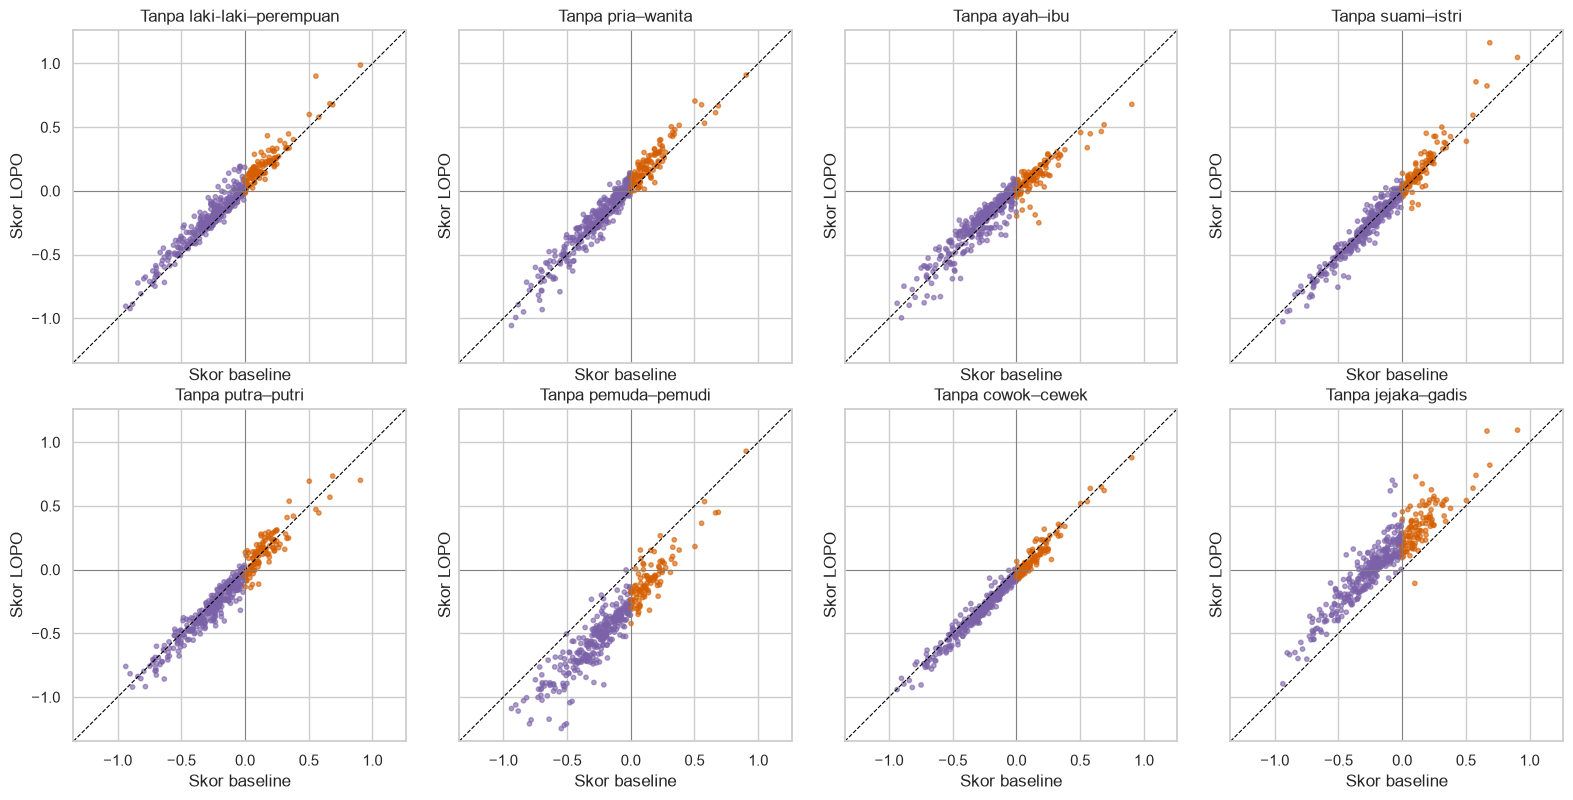

**Delapan kondisi:** 3320 skor ulang menggunakan 14 atribut. Sebanyak 416 kombinasi jabatan–pasangan mengalami pembalikan positif↔negatif; kedekatan terhadap garis kesamaan dibaca bersama perubahan arah.

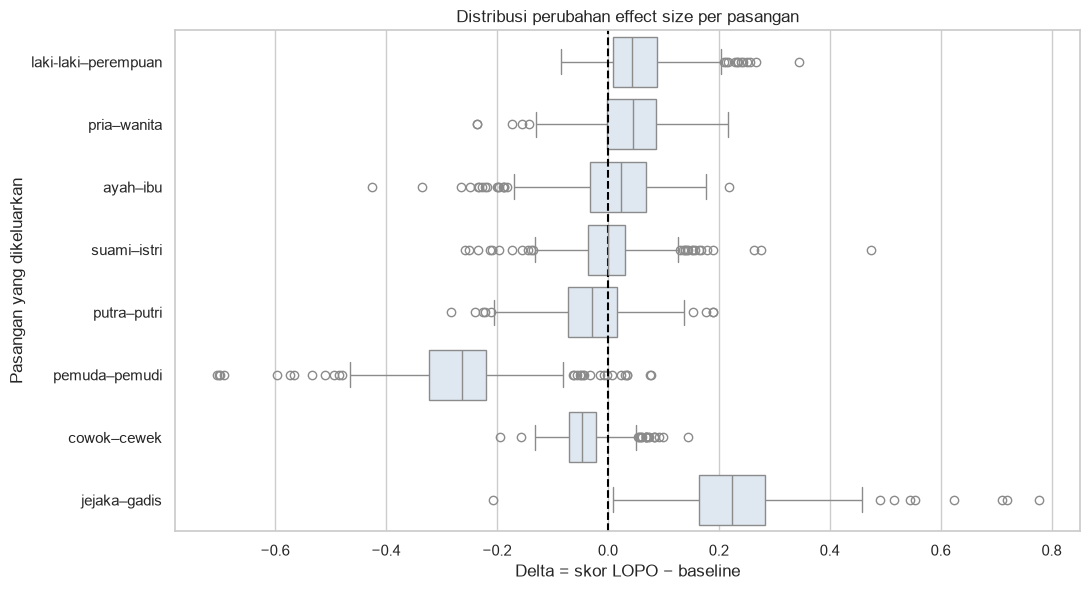

**Delta:** perubahan absolut maksimum seluruh kombinasi 0.7771. Boxplot delta mempertahankan tanda perubahan dan tidak memakai kategori stabil/tidak stabil.

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
lopo_limits = [min(results['effect_size'].min(), lopo_scores.min()) - 0.1,
               max(results['effect_size'].max(), lopo_scores.max()) + 0.1]
for j, (ax, label) in enumerate(zip(axes.flat, PAIR_LABELS)):
    ax.scatter(results['effect_size'], lopo_scores[:, j], c=results['direction'].map(PALETTE), s=10, alpha=0.6)
    ax.plot(lopo_limits, lopo_limits, '--', color='black', linewidth=0.8)
    ax.axhline(0, color='gray', linewidth=0.7)
    ax.axvline(0, color='gray', linewidth=0.7)
    ax.set(title=f'Tanpa {label}', xlim=lopo_limits, ylim=lopo_limits, aspect='equal',
           xlabel='Skor baseline', ylabel='Skor LOPO')
finish_figure(fig, 'rm3_scatter_delapan_kondisi', f"**Delapan kondisi:** {len(lopo_detail)} skor ulang menggunakan 14 atribut. Sebanyak {lopo_detail['sign_flip'].sum()} kombinasi jabatan–pasangan mengalami pembalikan positif↔negatif; kedekatan terhadap garis kesamaan dibaca bersama perubahan arah.")

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=lopo_detail, x='delta', y='pair_id', order=PAIR_ORDER, color='#DCE7F3', ax=ax)
ax.set_yticks(range(8), labels=PAIR_LABELS)
ax.axvline(0, linestyle='--', color='black')
ax.set(title='Distribusi perubahan effect size per pasangan', xlabel='Delta = skor LOPO − baseline', ylabel='Pasangan yang dikeluarkan')
finish_figure(fig, 'rm3_boxplot_delta', f"**Delta:** perubahan absolut maksimum seluruh kombinasi {lopo_detail['abs_delta'].max():.4f}. Boxplot delta mempertahankan tanda perubahan dan tidak memakai kategori stabil/tidak stabil.")

### Heatmap delta: subset terbaca dan seluruh jabatan

Notebook menampilkan 30 jabatan dengan `max_abs_delta` terbesar (ties urutan kode). Rentang warna simetris dan berpusat nol menggunakan maksimum absolut dari **seluruh 3.320 delta**. Seluruh 415 jabatan diekspor sebagai halaman PNG 300 dpi + SVG (25 baris per halaman) serta tabel HTML lengkap. Identitas kode dan nama pada setiap baris menjaga penelusuran. Warna menyatakan arah **perubahan**, bukan langsung arah gender skor akhir.

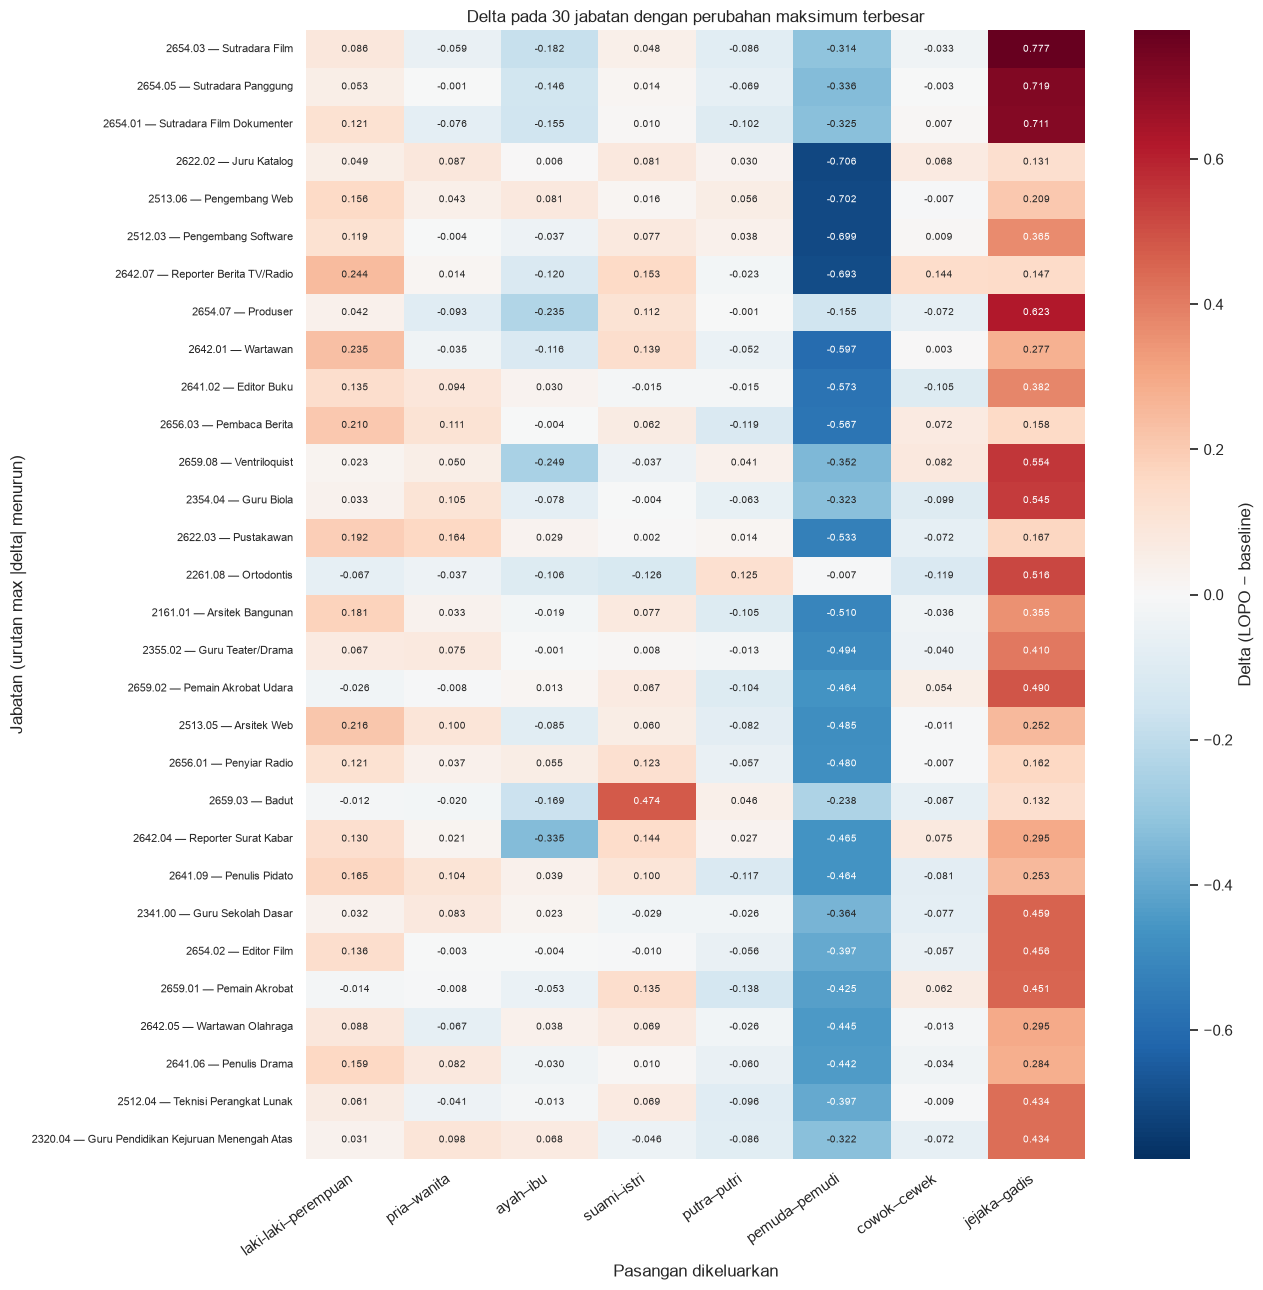

**Heatmap subset:** 30 jabatan dipilih dari 415 berdasarkan max |delta|. Warna memakai rentang ±0.7771. [Seluruh jabatan dalam HTML](../outputs/analisis_utama/scweat_20261014T224206_381549+0700/figures/lopo_heatmap_lengkap.html); halaman statis lengkap tersedia di folder figures run ini.

Heatmap lengkap: 17 halaman; seluruh 415 jabatan.


In [16]:
delta_wide = lopo_detail.pivot(index='occupation_code', columns='pair_id', values='delta').reindex(columns=PAIR_ORDER)
heatmap_limit = float(np.abs(delta_wide.to_numpy()).max())
heatmap_limit = max(heatmap_limit, CONFIG['atol'])
name_lookup = data.set_index('occupation_code')['occupation_name_raw'].to_dict()
selected_codes = job_sensitivity.sort_values(['max_abs_delta', 'occupation_code'], ascending=[False, True]).head(CONFIG['heatmap_top_n'])['occupation_code']
selected_delta = delta_wide.loc[selected_codes]
fig, ax = plt.subplots(figsize=(13, 13))
sns.heatmap(selected_delta, cmap='RdBu_r', center=0, vmin=-heatmap_limit, vmax=heatmap_limit,
            annot=True, fmt='.3f', annot_kws={'fontsize': 7}, ax=ax, cbar_kws={'label': 'Delta (LOPO − baseline)'})
ax.set_yticklabels([fill(f'{c} — {name_lookup[c]}', 49) for c in selected_delta.index], rotation=0, fontsize=8)
ax.set_xticklabels(PAIR_LABELS, rotation=35, ha='right')
ax.set(title='Delta pada 30 jabatan dengan perubahan maksimum terbesar', xlabel='Pasangan dikeluarkan', ylabel='Jabatan (urutan max |delta| menurun)')
finish_figure(fig, 'rm3_heatmap_top30', f"**Heatmap subset:** {len(selected_delta)} jabatan dipilih dari {len(data)} berdasarkan max |delta|. Warna memakai rentang ±{heatmap_limit:.4f}. [Seluruh jabatan dalam HTML](../outputs/analisis_utama/{RUN_ID}/figures/lopo_heatmap_lengkap.html); halaman statis lengkap tersedia di folder figures run ini.")

full_delta = delta_wide.sort_index().copy()
full_delta.index = [f'{c} — {name_lookup[c]}' for c in full_delta.index]
full_delta.columns = PAIR_LABELS
html = full_delta.style.background_gradient(cmap='RdBu_r', vmin=-heatmap_limit, vmax=heatmap_limit, axis=None).format('{:.6f}').to_html()
(FIGURE_DIR / 'lopo_heatmap_lengkap.html').write_text(
    '<!doctype html><html lang="id"><meta charset="utf-8"><title>Heatmap delta seluruh jabatan</title>'
    '<style>body{font-family:system-ui;margin:24px}th{position:sticky;top:0;background:white}td{padding:6px}table{border-collapse:collapse}</style>'
    f'<h1>Delta LOPO seluruh {len(data)} jabatan</h1><p>Run {RUN_ID}. Delta = LOPO − baseline; urutan kode. Skala simetris ±{heatmap_limit:.6f}. Warna adalah perubahan skor, bukan arah gender skor akhir.</p>' + html + '</html>', encoding='utf-8')
for page, start in enumerate(range(0, len(delta_wide), CONFIG['heatmap_rows_per_page']), start=1):
    page_delta = delta_wide.sort_index().iloc[start:start + CONFIG['heatmap_rows_per_page']]
    fig, ax = plt.subplots(figsize=(13, max(5, len(page_delta) * 0.38 + 2.5)))
    sns.heatmap(page_delta, cmap='RdBu_r', center=0, vmin=-heatmap_limit, vmax=heatmap_limit,
                annot=True, fmt='.3f', annot_kws={'fontsize': 7}, ax=ax, cbar_kws={'label': 'Delta (LOPO − baseline)'})
    ax.set_yticklabels([fill(f'{c} — {name_lookup[c]}', 52) for c in page_delta.index], rotation=0, fontsize=8)
    ax.set_xticklabels(PAIR_LABELS, rotation=35, ha='right')
    ax.set(title=f'Delta seluruh jabatan — halaman {page} (baris {start + 1}–{start + len(page_delta)})',
           xlabel='Pasangan dikeluarkan', ylabel='Jabatan, urutan kode')
    fig.tight_layout()
    name = f'rm3_heatmap_lengkap_halaman_{page:02d}'
    fig.savefig(FIGURE_DIR / (name + '.png'), dpi=CONFIG['figure_dpi'], bbox_inches='tight')
    fig.savefig(FIGURE_DIR / (name + '.svg'), bbox_inches='tight')
    plt.close(fig)
    FIGURES.append({'name': name, 'caption': f'Delta seluruh jabatan, halaman {page}, skala ±{heatmap_limit:.6f}.',
                    'png': 'figures/' + name + '.png', 'svg': 'figures/' + name + '.svg'})
print('Heatmap lengkap:', page, 'halaman; seluruh', len(delta_wide), 'jabatan.')

### Pembalikan arah, korelasi peringkat, dan jumlah arah dipertahankan

Spearman (Persamaan 2.12) hanya ukuran deskriptif tanpa p-value. Korelasi tinggi dapat berdampingan dengan pembalikan pada sebagian jabatan. Jumlah kondisi yang mempertahankan arah dilaporkan 0–8 tanpa ambang kategori baru.

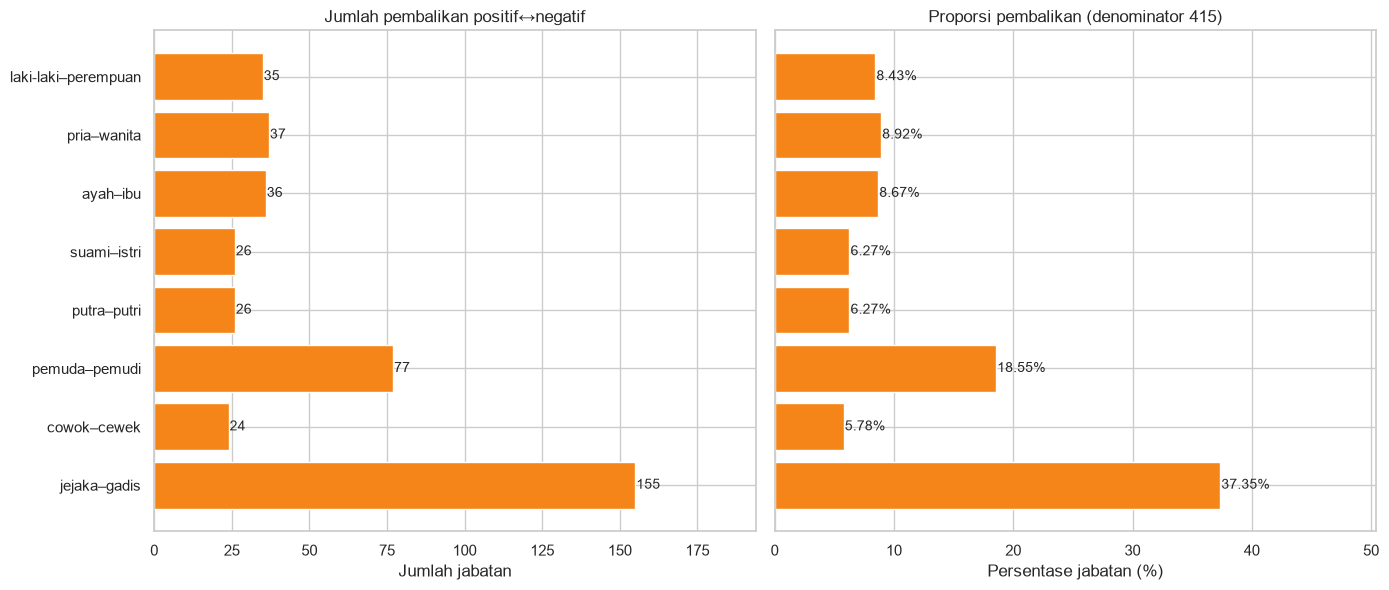

**Pembalikan:** pasangan dengan jumlah terbanyak adalah jejaka–gadis (155 dari 415). Transisi melibatkan nol: 0 kombinasi, dicatat terpisah.

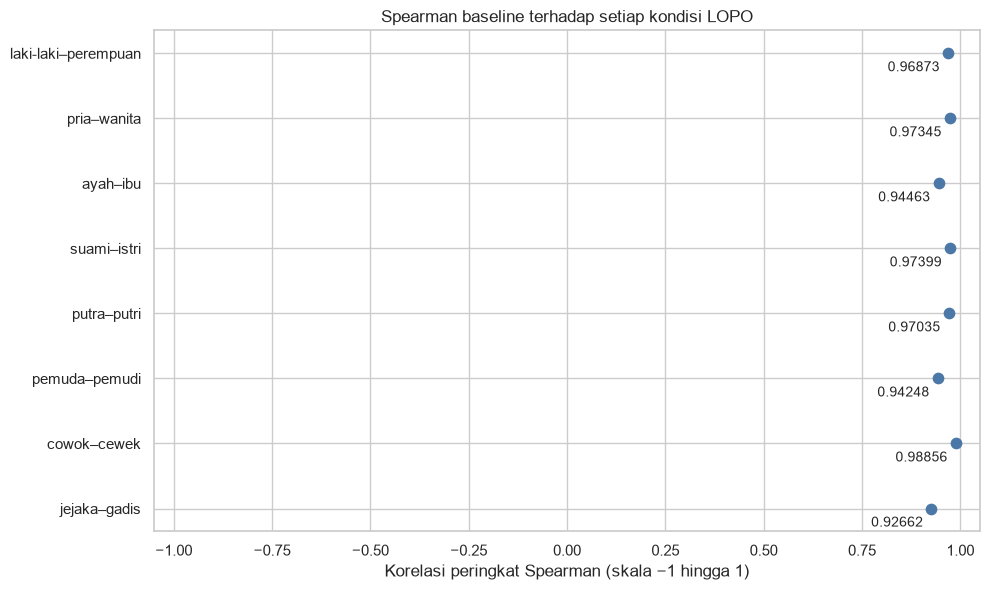

**Peringkat:** Spearman deskriptif berkisar 0.92662–0.98856. Nilai tinggi tidak menghilangkan kemungkinan pembalikan arah; tidak ada p-value korelasi.

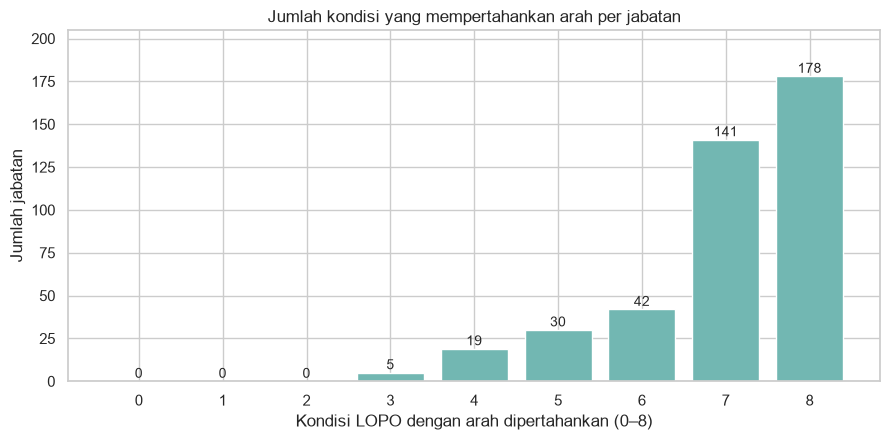

**Arah:** 178 dari 415 jabatan mempertahankan arah pada seluruh delapan kondisi; 237 berubah arah setidaknya sekali. Transisi nol dipisahkan dari pembalikan positif↔negatif.

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
axes[0].barh(np.arange(8), pair_sensitivity['n_sign_flips'], color='#F58518')
axes[1].barh(np.arange(8), pair_sensitivity['proportion_sign_flips'] * 100, color='#F58518')
for i, row in enumerate(pair_sensitivity.itertuples()):
    axes[0].text(row.n_sign_flips + 0.3, i, str(row.n_sign_flips), va='center')
    axes[1].text(row.proportion_sign_flips * 100 + 0.1, i, f'{row.proportion_sign_flips:.2%}', va='center')
axes[0].set_yticks(range(8), labels=PAIR_LABELS)
axes[0].invert_yaxis()
axes[0].set(title='Jumlah pembalikan positif↔negatif', xlabel='Jumlah jabatan')
axes[1].set(title='Proporsi pembalikan (denominator 415)', xlabel='Persentase jabatan (%)')
axes[0].set_xlim(0, max(5, pair_sensitivity['n_sign_flips'].max() * 1.25))
axes[1].set_xlim(0, max(1, pair_sensitivity['proportion_sign_flips'].max() * 100 * 1.35))
finish_figure(fig, 'rm3_pembalikan_arah', f"**Pembalikan:** pasangan dengan jumlah terbanyak adalah {pair_sensitivity.loc[pair_sensitivity['n_sign_flips'].idxmax(), 'pair_label']} ({pair_sensitivity['n_sign_flips'].max()} dari 415). Transisi melibatkan nol: {pair_sensitivity['n_zero_transitions'].sum()} kombinasi, dicatat terpisah.")

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(pair_sensitivity['spearman_rho'], np.arange(8), s=55, color='#4C78A8')
for i, value in enumerate(pair_sensitivity['spearman_rho']):
    if np.isfinite(value): ax.annotate(f'{value:.5f}', (value, i), xytext=(-6, -13), textcoords='offset points', ha='right')
    else: ax.text(0, i, 'Tidak terdefinisi: skor konstan', va='center')
ax.set_yticks(range(8), labels=PAIR_LABELS)
ax.invert_yaxis()
ax.set(title='Spearman baseline terhadap setiap kondisi LOPO', xlabel='Korelasi peringkat Spearman (skala −1 hingga 1)', xlim=(-1.05, 1.05))
finish_figure(fig, 'rm3_spearman', f"**Peringkat:** Spearman deskriptif berkisar {pair_sensitivity['spearman_rho'].min():.5f}–{pair_sensitivity['spearman_rho'].max():.5f}. Nilai tinggi tidak menghilangkan kemungkinan pembalikan arah; tidak ada p-value korelasi.")

retained_counts = job_sensitivity['n_direction_retained'].value_counts().reindex(range(9), fill_value=0)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(retained_counts.index, retained_counts.values, color='#72B7B2')
for i, n in retained_counts.items(): ax.text(i, n + 2, str(n), ha='center')
ax.set(title='Jumlah kondisi yang mempertahankan arah per jabatan', xlabel='Kondisi LOPO dengan arah dipertahankan (0–8)',
       ylabel='Jumlah jabatan', xticks=range(9), ylim=(0, retained_counts.max() * 1.15))
finish_figure(fig, 'rm3_distribusi_arah_dipertahankan', f"**Arah:** {retained_counts.loc[8]} dari 415 jabatan mempertahankan arah pada seluruh delapan kondisi; {415 - retained_counts.loc[8]} berubah arah setidaknya sekali. Transisi nol dipisahkan dari pembalikan positif↔negatif.")

### Perubahan maksimum dan jabatan paling sensitif

Perubahan maksimum dihitung per jabatan dari delapan kondisi. Semua pasangan yang terikat pada maksimum dicatat (toleransi numerik yang sama); daftar jabatan paling sensitif diurutkan berdasarkan maksimum perubahan absolut, lalu kode.

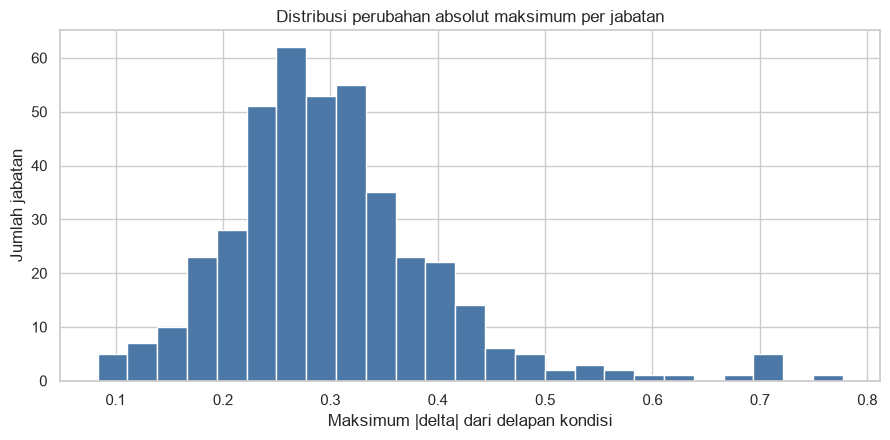

**Perubahan maksimum:** median 0.2874, maksimum 0.7771, pada 415 jabatan.

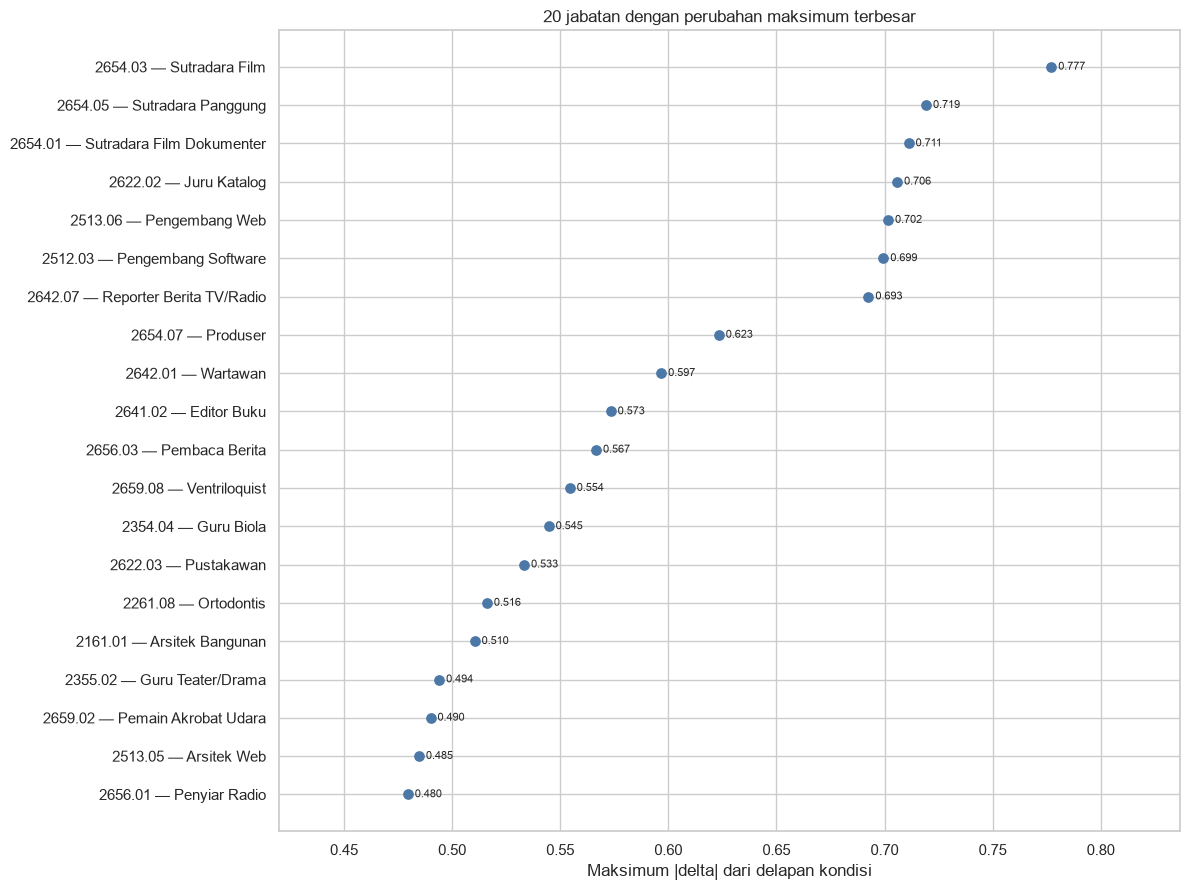

**Pemilihan:** 20 dari 415 jabatan berdasarkan max |delta|, ties diurutkan kode; seluruh daftar serta pasangan pemicu tersedia pada `lopo_ringkasan_jabatan.csv`. Jabatan maksimum: 2654.03.

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(job_sensitivity['max_abs_delta'], bins=25, color='#4C78A8', edgecolor='white')
ax.set(title='Distribusi perubahan absolut maksimum per jabatan', xlabel='Maksimum |delta| dari delapan kondisi', ylabel='Jumlah jabatan')
finish_figure(fig, 'rm3_histogram_perubahan_maksimum', f"**Perubahan maksimum:** median {job_sensitivity['max_abs_delta'].median():.4f}, maksimum {job_sensitivity['max_abs_delta'].max():.4f}, pada {len(job_sensitivity)} jabatan.")

sensitive_jobs = job_sensitivity.sort_values(['max_abs_delta', 'occupation_code'], ascending=[False, True]).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 9))
ax.scatter(sensitive_jobs['max_abs_delta'], np.arange(len(sensitive_jobs)), s=45, color='#4C78A8')
for i, row in enumerate(sensitive_jobs.itertuples()):
    ax.annotate(f'{row.max_abs_delta:.3f}', (row.max_abs_delta, i), xytext=(5, 0), textcoords='offset points', va='center', fontsize=8)
ax.set_yticks(np.arange(len(sensitive_jobs)), labels=[fill(f'{r.occupation_code} — {r.occupation_name_raw}', 54) for r in sensitive_jobs.itertuples()])
ax.set(title='20 jabatan dengan perubahan maksimum terbesar', xlabel='Maksimum |delta| dari delapan kondisi')
ax.margins(x=0.2)
finish_figure(fig, 'rm3_jabatan_paling_sensitif', f"**Pemilihan:** 20 dari {len(data)} jabatan berdasarkan max |delta|, ties diurutkan kode; seluruh daftar serta pasangan pemicu tersedia pada `lopo_ringkasan_jabatan.csv`. Jabatan maksimum: {job_sensitivity.loc[job_sensitivity['max_abs_delta'].idxmax(), 'occupation_code']}.")

## 7. Validasi numerik independen dan invariansi yang dihitung ulang

Pemeriksaan memakai data aktual, bukan angka skor eksperimen lama. Cosine diperiksa dengan rumus umum. P-value beberapa jabatan dihitung ulang memakai loop referensi skalar yang terpisah dari perkalian matriks. Enumerator, komplemen, `ddof=0`, pertukaran label, BH independen, dan LOPO diuji. Invariansi baris/atribut **membentuk cosine baru dan menghitung ulang skor, p-value, BH, serta seluruh LOPO** sebelum merge berdasarkan kode (dan pasangan untuk LOPO).

In [19]:
t0 = time.perf_counter()
sample_indices = np.unique(np.r_[np.linspace(0, len(data) - 1, 6, dtype=int),
    data.index[data['occupation_code'].isin(['2111.10', '2162.00', '2142.04'])].to_numpy()])
for i in sample_indices:
    for j in [0, 3, 8, 15]:
        general_cosine = 1 - cosine_distance(target_raw[i], attribute_raw[j])
        assert np.isclose(cosines[i, j], general_cosine, atol=CONFIG['atol'], rtol=CONFIG['rtol'])
CHECKS.append({'check': 'Cosine dot unit vs rumus umum', 'observed': len(sample_indices) * 4, 'expected': 'semua cocok', 'status': True, 'notes': 'Target/token mentah actual, scipy.spatial.distance.cosine.'})
assert np.array_equal(permutation_signs[::-1], -permutation_signs)
sample_perms = cosines[sample_indices] @ permutation_signs.T
assert np.allclose(sample_perms[:, ::-1], -sample_perms, atol=CONFIG['atol'], rtol=CONFIG['rtol'])
CHECKS.append({'check': 'Enumerator unik dan simetri komplemen', 'observed': len(partitions), 'expected': 12870, 'status': True, 'notes': 'Komplemen semua partisi dicek; statistik sampel berlawanan tanda.'})
reference_rows = []
for i in sample_indices:
    row = cosines[i]
    observed_ref = sum(float(row[k]) for k in range(8)) - sum(float(row[k]) for k in range(8, 16))
    mean_ref = sum(float(v) for v in row) / 16
    sd_ref = np.sqrt(sum((float(v) - mean_ref) ** 2 for v in row) / 16)
    effect_ref = ((sum(float(row[k]) for k in range(8)) / 8) - (sum(float(row[k]) for k in range(8, 16)) / 8)) / sd_ref
    extreme_ref = 0
    for combination in itertools.combinations(range(16), 8):
        selected = set(combination)
        statistic = sum(float(row[k]) for k in range(16) if k in selected) - sum(float(row[k]) for k in range(16) if k not in selected)
        extreme_ref += (abs(statistic) >= abs(observed_ref) or
                        np.isclose(abs(statistic), abs(observed_ref), atol=CONFIG['atol'], rtol=CONFIG['rtol']))
    assert extreme_ref == int(results.iloc[i]['extreme_count'])
    assert np.isclose(effect_ref, results.iloc[i]['effect_size'], atol=CONFIG['atol'], rtol=CONFIG['rtol'])
    reference_rows.append({'occupation_code': data.iloc[i]['occupation_code'], 'T_reference': observed_ref,
        'std_reference_ddof0': sd_ref, 'effect_reference': effect_ref,
        'extreme_count_reference': int(extreme_ref), 'p_reference': extreme_ref / 12870})
reference_checks = pd.DataFrame(reference_rows)
assert results['p_raw'].gt(0).all() and results['p_raw'].le(1).all()
assert (results['extreme_count'] >= 2).all() and (results['extreme_count'] % 2 == 0).all()
assert np.array_equal(results['p_raw'].to_numpy(), results['extreme_count'].to_numpy() / 12870)
assert np.allclose(results['std_cosine_all'], np.sqrt(((cosines - cosines.mean(axis=1, keepdims=True)) ** 2).sum(axis=1) / 16), atol=CONFIG['atol'], rtol=CONFIG['rtol'])
CHECKS.append({'check': 'Effect ddof=0 dan p-value referensi skalar', 'observed': len(sample_indices), 'expected': 'semua cocok', 'status': True, 'notes': '12870 pembagian dihitung ulang untuk setiap sampel, termasuk kode berekor nol.'})

sort_index = np.argsort(results['p_raw'].to_numpy(), kind='stable')
raw_sorted = results['p_raw'].to_numpy()[sort_index]
bh_reference_sorted = np.minimum(1, np.minimum.accumulate((raw_sorted * len(results) / np.arange(1, len(results) + 1))[::-1])[::-1])
bh_reference = np.empty(len(results)); bh_reference[sort_index] = bh_reference_sorted
assert np.allclose(bh_reference, results['p_adjusted'], atol=CONFIG['atol'], rtol=CONFIG['rtol'])
assert np.array_equal(bh_reference <= CONFIG['fdr_q'], results['reject_fdr'])
CHECKS.append({'check': 'BH independen global 415', 'observed': len(results), 'expected': 415, 'status': True, 'notes': 'Urut p, monotonic adjusted p, keputusan global cocok statsmodels.'})

swapped = measure_scweat(cosines, female_indices, male_indices, permutation_signs, CONFIG['atol'], CONFIG['rtol'], CONFIG['fdr_q'])
assert np.allclose(swapped['effect_size'], -results['effect_size'], atol=CONFIG['atol'], rtol=CONFIG['rtol'])
assert np.allclose(swapped['T_observed'], -results['T_observed'], atol=CONFIG['atol'], rtol=CONFIG['rtol'])
assert np.array_equal(swapped['p_raw'], results['p_raw']) and np.array_equal(swapped['reject_fdr'], results['reject_fdr'])
CHECKS.append({'check': 'Pertukaran label gender', 'observed': 415, 'expected': 'skor −baseline; p dua sisi sama', 'status': True, 'notes': 'Skor, T, p-value dan keputusan dihitung ulang.'})
display(reference_checks)

,occupation_code,T_reference,std_reference_ddof0,effect_reference,extreme_count_reference,p_reference
0,2111.01,-0.012971,0.051489,-0.031490,12300,0.955711
1,2111.10,0.063963,0.048711,0.164137,9770,0.759130
2,2142.04,-0.137425,0.050744,-0.338522,7122,0.553380
3,2145.01,-0.037656,0.059481,-0.079134,11360,0.882673
4,2162.00,-0.015828,0.040444,-0.048919,11952,0.928671
5,2230.01,-0.118591,0.054581,-0.271593,7896,0.613520
6,2355.01,-0.326476,0.049938,-0.817205,1506,0.117016
7,2632.05,0.060826,0.048338,0.157292,9942,0.772494
8,2659.08,-0.107750,0.030714,-0.438528,5412,0.420513


In [20]:
invariance_rows = []
for scenario in ['baris', 'atribut']:
    row_order = RNG.permutation(len(data)) if scenario == 'baris' else np.arange(len(data))
    attribute_order = RNG.permutation(16) if scenario == 'atribut' else np.arange(16)
    fresh_cosines = targets[row_order] @ attributes[attribute_order].T
    new_male = np.flatnonzero(attribute_order < 8)
    new_female = np.flatnonzero(attribute_order >= 8)
    fresh = measure_scweat(fresh_cosines, new_male, new_female, permutation_signs,
                           CONFIG['atol'], CONFIG['rtol'], CONFIG['fdr_q'])
    fresh_results = pd.concat([data.iloc[row_order][['occupation_code']].reset_index(drop=True), pd.DataFrame(fresh)], axis=1)
    fresh_results['rank_baseline'] = fresh_results['effect_size'].rank(ascending=False, method='average')
    comparison = results.merge(fresh_results, on='occupation_code', suffixes=('_baseline', '_recomputed'), validate='one_to_one')
    for column in ['effect_size', 'T_observed', 'p_raw', 'p_adjusted', 'std_cosine_all', 'rank_baseline']:
        assert np.allclose(comparison[column + '_baseline'], comparison[column + '_recomputed'], atol=CONFIG['atol'], rtol=CONFIG['rtol']), (scenario, column)
    assert np.array_equal(comparison['reject_fdr_baseline'], comparison['reject_fdr_recomputed'])
    for j, pair_id in enumerate(PAIR_ORDER):
        # Mapping pasangan ikut diacak; identitas istilah menentukan dua kolom yang dikeluarkan.
        remove_columns = np.flatnonzero(np.isin(attribute_order, [j, j + 8]))
        assert len(remove_columns) == 2 and set(attribute_order[remove_columns]) == {j, j + 8}
        keep_male = np.setdiff1d(new_male, remove_columns)
        keep_female = np.setdiff1d(new_female, remove_columns)
        keep_all = np.concatenate([keep_male, keep_female])
        assert len(keep_male) == len(keep_female) == 7
        fresh_lopo_std = fresh_cosines[:, keep_all].std(axis=1, ddof=0)
        fresh_lopo = (fresh_cosines[:, keep_male].mean(axis=1) - fresh_cosines[:, keep_female].mean(axis=1)) / fresh_lopo_std
        fresh_frame = pd.DataFrame({'occupation_code': data.iloc[row_order]['occupation_code'].to_numpy(),
            'effect_size_lopo': fresh_lopo, 'std_cosine_lopo': fresh_lopo_std,
            'delta': fresh_lopo - fresh['effect_size'],
            'rank_lopo': pd.Series(fresh_lopo).rank(ascending=False, method='average').to_numpy()})
        matched = lopo_detail.loc[lopo_detail['pair_id'].eq(pair_id)].merge(fresh_frame, on='occupation_code', suffixes=('_baseline', '_recomputed'), validate='one_to_one')
        for column in ['effect_size_lopo', 'std_cosine_lopo', 'delta', 'rank_lopo']:
            assert np.allclose(matched[column + '_baseline'], matched[column + '_recomputed'], atol=CONFIG['atol'], rtol=CONFIG['rtol']), (scenario, pair_id, column)
        new_direction = np.select([matched['effect_size_lopo_recomputed'] > CONFIG['zero_atol'], matched['effect_size_lopo_recomputed'] < -CONFIG['zero_atol']], ['positif', 'negatif'], default='nol')
        assert np.array_equal(new_direction, matched['direction_lopo'])
    max_error = float(np.abs(comparison['effect_size_baseline'] - comparison['effect_size_recomputed']).max())
    invariance_rows.append({'scenario': scenario, 'n_occupations': len(comparison), 'n_lopo_combinations': len(lopo_detail), 'max_effect_error': max_error, 'status': True})
    CHECKS.append({'check': 'Invariansi ' + scenario + ' dihitung ulang', 'observed': '415 utama + 3320 LOPO',
        'expected': 'sama berdasarkan kode', 'status': True, 'notes': f'Cosine, skor, p, BH, LOPO, delta, peringkat, arah; max error {max_error:.3g}.'})
invariance_checks = pd.DataFrame(invariance_rows)
display(invariance_checks)

# Referensi ddof=0 LOPO dihitung manual pada seluruh jabatan dan pasangan.
for j, pair_id in enumerate(PAIR_ORDER):
    keep = [k for k in range(16) if k not in [j, j + 8]]
    center = cosines[:, keep].mean(axis=1)
    sd_manual = np.sqrt(((cosines[:, keep] - center[:, None]) ** 2).sum(axis=1) / 14)
    subset = lopo_detail.loc[lopo_detail['pair_id'].eq(pair_id)].set_index('occupation_code').loc[data['occupation_code']]
    assert np.allclose(sd_manual, subset['std_cosine_lopo'], atol=CONFIG['atol'], rtol=CONFIG['rtol'])
    assert subset['n_attributes'].eq(14).all()
    assert np.array_equal(subset['removed_male_term'], np.repeat(TERMS[j], len(data)))
    assert np.array_equal(subset['removed_female_term'], np.repeat(TERMS[j + 8], len(data)))
assert np.allclose(lopo_detail['delta'], lopo_detail['effect_size_lopo'] - lopo_detail['effect_size_baseline'])
assert job_sensitivity['n_conditions'].eq(8).all()
assert np.allclose(job_sensitivity['proportion_direction_retained'], job_sensitivity['n_direction_retained'] / 8)
for row in group_summary.itertuples():
    subset = results.loc[results['submajor_group_code'].eq(row.submajor_group_code)]
    assert np.isclose(row.std_effect_size, np.sqrt(((subset['effect_size'] - subset['effect_size'].mean()) ** 2).sum() / len(subset)), atol=CONFIG['atol'], rtol=CONFIG['rtol'])
    assert row.n_significant_fdr == subset['reject_fdr'].sum()
CHECKS += [
    {'check': 'LOPO 3320 unik, pasangan dan penyebut 14', 'observed': len(lopo_detail), 'expected': 3320, 'status': True, 'notes': 'Seluruh penyebut dicek rumus manual ddof=0; delta, arah dan peringkat diperiksa.'},
    {'check': 'Ringkasan enam kelompok dari skor individual', 'observed': int(group_summary['n_occupations'].sum()), 'expected': 415, 'status': True, 'notes': 'SD populasi dan jumlah signifikan cocok nilai individual BH global.'},
]
TIMINGS['validation_seconds'] = time.perf_counter() - t0

,scenario,n_occupations,n_lopo_combinations,max_effect_error,status
0,baris,415,3320,2.553513e-15,True
1,atribut,415,3320,3.781480e-15,True


## 8. Ekspor hasil baru, audit, dan round-trip identitas

CSV menggunakan UTF-8 tanpa indeks; nilai analisis diekspor dengan presisi penuh, pembulatan hanya tampilan. Kolom list (`tokens`, token OOV, pasangan maksimum) diekspor sebagai JSON dalam CSV. Saat membaca ulang, semua kolom kode wajib `dtype=str`. Audit OOV memisahkan seluruh jabatan, tanpa OOV, dan memiliki OOV secara deskriptif tanpa mengubah sampel utama.

Manifest menyimpan hash sumber, lexical set, PDF, model, sumber notebook, versi paket/Python, Git/working tree, parameter, durasi, ukuran output, dan hasil pemeriksaan. Hash notebook dihitung dari jenis+isi cell tanpa output sehingga tetap dapat dicocokkan dengan notebook yang telah dieksekusi.

In [21]:
oov_summary_rows = []
for label, mask in [('seluruh_jabatan', np.ones(len(data), dtype=bool)),
                    ('tanpa_token_oov', ~data['has_oov'].to_numpy()),
                    ('memiliki_token_oov', data['has_oov'].to_numpy())]:
    subset = results.loc[mask]
    oov_summary_rows.append({'population': label, 'n_occupations': len(subset),
        'mean_effect_size': subset['effect_size'].mean(), 'median_effect_size': subset['effect_size'].median(),
        'std_effect_size_ddof0': subset['effect_size'].std(ddof=0),
        'n_positive': int(subset['direction'].eq('positif').sum()),
        'n_negative': int(subset['direction'].eq('negatif').sum()), 'n_zero': int(subset['direction'].eq('nol').sum()),
        'n_significant_global_fdr': int(subset['reject_fdr'].sum()),
        'note': 'Deskriptif; FDR tetap keputusan global, OOV tidak dibuang.'})
oov_summary = pd.DataFrame(oov_summary_rows)
display(oov_summary)

data_columns = ['occupation_code', 'occupation_name_raw', 'occupation_text', 'tokens', 'token_count',
    'raw_token_count', 'major_group_code', 'major_group_name', 'submajor_group_code', 'submajor_group_name',
    'group_code', 'group_name', 'subgroup_code', 'subgroup_name', 'source_document', 'source_page_pdf',
    'source_page_printed', 'include_analysis', 'exclusion_reason', 'oov_tokens', 'oov_token_count', 'has_oov']
OUTPUT_TABLES = {
    'tables/data_analisis.csv': data[data_columns],
    'tables/lexicon_gender.csv': lexicon,
    'tables/cosine_atribut.csv': cosine_table,
    'tables/hasil_scweat.csv': results,
    'tables/ringkasan_subgolongan.csv': group_summary,
    'tables/lopo_detail.csv': lopo_detail,
    'tables/lopo_ringkasan_jabatan.csv': job_sensitivity,
    'tables/lopo_ringkasan_pasangan.csv': pair_sensitivity,
    'tables/kontribusi_pasangan_per_jabatan.csv': pair_contributions,
    'audit/audit_preparasi.csv': audit_preparasi,
    'audit/audit_perubahan_teks.csv': audit_preparasi.loc[audit_preparasi['text_changed'] | audit_preparasi['token_count_changed']],
    'audit/audit_vektor.csv': audit_vektor,
    'audit/audit_token.csv': token_audit,
    'audit/audit_atribut.csv': attribute_audit,
    'audit/audit_lexicon_historis.csv': lexical_comparison,
    'audit/audit_input.csv': pd.DataFrame(input_metadata),
    'audit/audit_token_composition.csv': token_composition,
    'audit/audit_oov_ringkasan.csv': oov_summary,
    'audit/validasi_referensi.csv': reference_checks,
    'audit/validasi_invariansi.csv': invariance_checks,
    'audit/caption_figures.csv': pd.DataFrame(FIGURES),
}
schema_rows = []
for relative_path, frame in OUTPUT_TABLES.items():
    exported = frame.copy()
    for column in exported.columns:
        if exported[column].map(lambda value: isinstance(value, list)).any():
            exported[column] = exported[column].map(lambda value: json.dumps(value, ensure_ascii=False) if isinstance(value, list) else value)
        schema_rows.append({'file': relative_path, 'column': column, 'dtype_in_memory': str(frame[column].dtype),
                            'csv_list_encoding': 'JSON' if frame[column].map(lambda v: isinstance(v, list)).any() else ''})
    exported.to_csv(RUN_DIR / relative_path, index=False, encoding='utf-8')
    readback = pd.read_csv(RUN_DIR / relative_path,
        dtype={c: str for c in exported.columns if c.endswith('_code') or c == 'pair_id'}, keep_default_na=False)
    assert len(readback) == len(frame), relative_path
    for column in [c for c in frame.columns if c.endswith('_code') or c == 'pair_id']:
        assert readback[column].tolist() == frame[column].astype(str).tolist(), (relative_path, column)
pd.DataFrame(schema_rows).to_csv(AUDIT_DIR / 'schema_output.csv', index=False, encoding='utf-8')
result_readback = pd.read_csv(TABLE_DIR / 'hasil_scweat.csv', dtype={'occupation_code': str, 'submajor_group_code': str})
assert result_readback['occupation_code'].tolist() == results['occupation_code'].tolist()
assert result_readback['occupation_code'].isin(['2111.10', '2162.00']).sum() == 2
assert np.allclose(result_readback['effect_size'], results['effect_size'], atol=CONFIG['atol'], rtol=CONFIG['rtol'])
assert np.allclose(result_readback['p_raw'], results['p_raw'], atol=CONFIG['atol'], rtol=CONFIG['rtol'])
CHECKS.append({'check': 'Round-trip seluruh CSV mempertahankan kode', 'observed': len(OUTPUT_TABLES),
    'expected': 'seluruh identitas utuh', 'status': True, 'notes': 'Kode dibaca string; 2111.10 dan 2162.00 serta digit nol akhir tetap utuh.'})
CHECKS.append({'check': 'Ekspor hasil lengkap', 'observed': '415 / 6 / 3320 / 415 / 8',
    'expected': 'utama / kelompok / LOPO / jabatan / pasangan', 'status': True,
    'notes': 'Seluruh tabel CSV dan visual PNG 300 dpi/SVG serta heatmap lengkap tersedia.'})
display(Markdown(f"Hasil lengkap berada pada [run `{RUN_ID}`](../outputs/analisis_utama/{RUN_ID}/). Tabel yang ditampilkan hanya cuplikan; seluruh observasi tersedia dalam CSV. Audit perubahan teks memuat semua {len(OUTPUT_TABLES['audit/audit_perubahan_teks.csv'])} baris terdampak dari input 501 entri."))

,population,n_occupations,mean_effect_size,median_effect_size,std_effect_size_ddof0,n_positive,n_negative,n_zero,n_significant_global_fdr,note
0,seluruh_jabatan,415,-0.170002,-0.167623,0.271714,105,310,0,0,"Deskriptif; FDR tetap keputusan global, OOV ti..."
1,tanpa_token_oov,410,-0.170835,-0.173646,0.271459,103,307,0,0,"Deskriptif; FDR tetap keputusan global, OOV ti..."
2,memiliki_token_oov,5,-0.101769,-0.034057,0.283661,2,3,0,0,"Deskriptif; FDR tetap keputusan global, OOV ti..."


Hasil lengkap berada pada [run `scweat_20261014T224206_381549+0700`](../outputs/analisis_utama/scweat_20261014T224206_381549+0700/). Tabel yang ditampilkan hanya cuplikan; seluruh observasi tersedia dalam CSV. Audit perubahan teks memuat semua 501 baris terdampak dari input 501 entri.

## 9. Jawaban masing-masing rumusan masalah dan batas interpretasi

Jawaban berikut dibuat dari nilai aktual pada run ini, terpisah untuk tiap RM. Pemilihan delapan pasangan mengikuti proposal; kualitas semantiknya dan konteks usia, kekerabatan, perkawinan, serta register membatasi interpretasi. Tidak ada pemilihan model atau penghapusan pasangan berdasarkan temuan yang lebih menarik.

In [22]:
direction_counts = results['direction'].value_counts().reindex(['positif', 'negatif', 'nol'], fill_value=0)
highest_mean = group_summary.loc[group_summary['mean_effect_size'].idxmax()]
lowest_mean = group_summary.loc[group_summary['mean_effect_size'].idxmin()]
largest_pair = pair_sensitivity.loc[pair_sensitivity['mean_abs_delta'].idxmax()]
rm_answers = {
    'RM1': f"Pada {len(results)} jabatan, terdapat {direction_counts['positif']} skor positif, {direction_counts['negatif']} negatif, dan {direction_counts['nol']} nol. Effect size rata-rata {results['effect_size'].mean():.6f}, median {results['effect_size'].median():.6f}, rentang {results['effect_size'].min():.6f}–{results['effect_size'].max():.6f}. Hasil mentah p≤0,05: {results['reject_raw'].sum()}; setelah BH global: {results['reject_fdr'].sum()}. Tidak signifikan bukan bukti tidak ada asosiasi.",
    'RM2': f"Enam kelompok memiliki jumlah {', '.join(str(v) for v in group_summary['n_occupations'])}. Rata-rata tertinggi pada {highest_mean['submajor_group_code']} ({highest_mean['mean_effect_size']:.6f}), terendah pada {lowest_mean['submajor_group_code']} ({lowest_mean['mean_effect_size']:.6f}); SD kelompok {group_summary['std_effect_size'].min():.6f}–{group_summary['std_effect_size'].max():.6f}. Perbandingan mean, median, rentang, proporsi dan signifikansi bersifat deskriptif; tidak ada uji beda kelompok.",
    'RM3': f"Dari delapan kondisi, {job_sensitivity['n_direction_retained'].eq(8).sum()} jabatan mempertahankan arah seluruhnya, {job_sensitivity['n_sign_flips'].gt(0).sum()} mengalami pembalikan positif↔negatif pada setidaknya satu kondisi. Pasangan dengan mean |delta| terbesar: {largest_pair['pair_label']} ({largest_pair['mean_abs_delta']:.6f}); perubahan absolut maksimum seluruh jabatan {job_sensitivity['max_abs_delta'].max():.6f}. Spearman {pair_sensitivity['spearman_rho'].min():.6f}–{pair_sensitivity['spearman_rho'].max():.6f}; korelasi tinggi dapat bersama pembalikan. LOPO tidak menjalankan uji signifikansi tambahan.",
}
for question, answer in rm_answers.items(): display(Markdown(f'**{question}.** {answer}'))
display(Markdown('**Batas:** asosiasi intrinsik dalam fastText serta sensitivitas pilihan atribut. Bukan bukti diskriminasi, fakta masyarakat, komposisi tenaga kerja, atau kelayakan gender suatu pekerjaan. Agregasi tidak menangkap urutan/konteks; klasifikasi ekstraksi bukan salinan resmi KBJI yang telah diverifikasi menyeluruh.'))
(AUDIT_DIR / 'jawaban_rm.json').write_text(json.dumps(rm_answers, indent=2, ensure_ascii=False), encoding='utf-8')

**RM1.** Pada 415 jabatan, terdapat 105 skor positif, 310 negatif, dan 0 nol. Effect size rata-rata -0.170002, median -0.167623, rentang -0.935940–0.905523. Hasil mentah p≤0,05: 0; setelah BH global: 0. Tidak signifikan bukan bukti tidak ada asosiasi.

**RM2.** Enam kelompok memiliki jumlah 138, 74, 42, 29, 26, 106. Rata-rata tertinggi pada 21 (-0.100979), terendah pada 23 (-0.341921); SD kelompok 0.206298–0.312722. Perbandingan mean, median, rentang, proporsi dan signifikansi bersifat deskriptif; tidak ada uji beda kelompok.

**RM3.** Dari delapan kondisi, 178 jabatan mempertahankan arah seluruhnya, 237 mengalami pembalikan positif↔negatif pada setidaknya satu kondisi. Pasangan dengan mean |delta| terbesar: pemuda–pemudi (0.267038); perubahan absolut maksimum seluruh jabatan 0.777140. Spearman 0.926615–0.988565; korelasi tinggi dapat bersama pembalikan. LOPO tidak menjalankan uji signifikansi tambahan.

**Batas:** asosiasi intrinsik dalam fastText serta sensitivitas pilihan atribut. Bukan bukti diskriminasi, fakta masyarakat, komposisi tenaga kerja, atau kelayakan gender suatu pekerjaan. Agregasi tidak menangkap urutan/konteks; klasifikasi ekstraksi bukan salinan resmi KBJI yang telah diverifikasi menyeluruh.

926

## 10. Assertion akhir, tabel quality control, dan finalisasi manifest

Status PASS hanya dicatat setelah pemeriksaan aktual selesai. Cell terakhir menegaskan ukuran keluaran, seluruh QC, dan ketersediaan visual; manifest berstatus `complete` hanya ditulis setelah assertion lolos. Durasi tidak mencakup pembukaan antarmuka notebook.

In [23]:
assert CONFIG['ddof'] == 0 and len(results) == 415 and len(group_summary) == 6
assert len(lopo_detail) == 3320 and len(job_sensitivity) == 415 and len(pair_sensitivity) == 8
assert np.isfinite(results['effect_size']).all() and np.isfinite(lopo_detail['effect_size_lopo']).all()
assert len(FIGURES) >= 20
assert all((RUN_DIR / item['png']).is_file() and (RUN_DIR / item['svg']).is_file() for item in FIGURES)
quality_control = pd.DataFrame(CHECKS)
assert quality_control['status'].all()
quality_control['status_label'] = np.where(quality_control['status'], 'PASS', 'FAIL')
quality_control.to_csv(AUDIT_DIR / 'validasi.csv', index=False, encoding='utf-8')
TIMINGS['total_elapsed_seconds'] = (datetime.now(JAKARTA) - START).total_seconds()
pd.DataFrame(TIMINGS.items(), columns=['stage', 'seconds']).to_csv(AUDIT_DIR / 'durasi.csv', index=False, encoding='utf-8')
output_metadata = [{'path': str(p.relative_to(RUN_DIR)).replace('\\', '/'), 'size_bytes': p.stat().st_size, 'sha256': sha256_file(p)}
                   for p in sorted(RUN_DIR.rglob('*')) if p.is_file() and p.name != 'manifest_run.json']
MANIFEST.update({'status': 'complete', 'end_time': datetime.now(JAKARTA).isoformat(),
    'inputs': input_metadata, 'model': model_metadata, 'timings_seconds': TIMINGS,
    'counts': {'raw_occupations': len(source), 'residual': int(source['residual_recomputed'].sum()),
        'gender_leakage': int(source['gender_leakage_recomputed'].sum()), 'occupations': len(data),
        'submajor_groups': len(group_summary), 'gender_pairs': len(lexicon), 'attributes': len(TERMS),
        'partitions': len(partitions), 'lopo_combinations': len(lopo_detail), 'quality_checks': len(quality_control),
        'figures_static': len(FIGURES), 'heatmap_pages': len([x for x in FIGURES if 'lengkap_halaman' in x['name']])},
    'results_summary': {'direction_counts': {k: int(v) for k, v in direction_counts.items()},
        'raw_significant': int(results['reject_raw'].sum()), 'fdr_significant': int(results['reject_fdr'].sum()),
        'mean_effect_size': float(results['effect_size'].mean()), 'median_effect_size': float(results['effect_size'].median()),
        'jobs_all_directions_retained': int(job_sensitivity['n_direction_retained'].eq(8).sum()),
        'jobs_with_sign_flip': int(job_sensitivity['n_sign_flips'].gt(0).sum())},
    'quality_control_passed': bool(quality_control['status'].all()), 'rm_answers': rm_answers, 'outputs': output_metadata})
(AUDIT_DIR / 'manifest_run.json').write_text(json.dumps(MANIFEST, indent=2, ensure_ascii=False), encoding='utf-8')
(ROOT / 'outputs' / 'analisis_utama' / 'LATEST_RUN.txt').write_text(RUN_ID + '\n', encoding='utf-8')
display(quality_control[['check', 'observed', 'expected', 'status_label', 'notes']])
display(pd.DataFrame(TIMINGS.items(), columns=['tahap', 'durasi_detik']))
print('COMPLETE:', RUN_ID, '| Semua', len(quality_control), 'pemeriksaan PASS.')

,check,observed,expected,status_label,notes
0,Seleksi dihitung ulang dan cocok sumber,501,501,PASS,Boolean diparse eksplisit; residual dan leakag...
1,415 kode string unik; kelompok sesuai,415,415,PASS,"{""21"": 138, ""22"": 74, ""23"": 42, ""24"": 29, ""25""..."
2,Nama asli terverifikasi seluruh kode CSV v2,501,501,PASS,Hanya nama mentah; representasi/hasil lama tid...
3,Delapan pasangan dan 16 istilah unik,16,16,PASS,Urutan proposal dan pair_id kanonis.
4,Vektor 300 dimensi finite dan norma satu,"(415, 300)",415 × 300; 16 × 300,PASS,Vektor token/target/atribut dicek sebelum dan ...
5,Cosine dot unit vs rumus umum,36,semua cocok,PASS,"Target/token mentah actual, scipy.spatial.dist..."
6,Enumerator unik dan simetri komplemen,12870,12870,PASS,Komplemen semua partisi dicek; statistik sampe...
7,Effect ddof=0 dan p-value referensi skalar,9,semua cocok,PASS,12870 pembagian dihitung ulang untuk setiap sa...
8,BH independen global 415,415,415,PASS,"Urut p, monotonic adjusted p, keputusan global..."
9,Pertukaran label gender,415,skor −baseline; p dua sisi sama,PASS,"Skor, T, p-value dan keputusan dihitung ulang."


,tahap,durasi_detik
0,data_preparation_seconds,0.137985
1,input_hash_seconds,11.197344
2,model_load_seconds,18.797978
3,embedding_seconds,0.399329
4,main_scweat_seconds,0.139718
5,lopo_seconds,0.863058
6,validation_seconds,2.166891
7,total_elapsed_seconds,115.033881


COMPLETE: scweat_20261014T224206_381549+0700 | Semua 16 pemeriksaan PASS.
